# Учебное исследование территории: Астрахань

Ноутбук показывает, как с помощью **BlocksNet 1.0.0a9** собрать данные о городе Астрахани, нарезать кварталы и рассчитать показатели из примера `examples/pipeline.ipynb`.

**Что делает ноутбук:**

1. Скачивает данные OpenStreetMap: дороги, железные дороги, воду, здания, больницы и поликлиники.
2. Нарезает город на кварталы и назначает назначение территории (land use).
3. Скачивает пешеходный граф и считает время в пути между кварталами в минутах.
4. Агрегирует здания и услуги, считает обеспеченность, плотность и морфотипы.

**Источники данных и методик:**

- OpenStreetMap (© участники OpenStreetMap, лицензия ODbL) — выгрузка Geofabrik (`south-fed-district-latest.osm.pbf`) и OSMnx.
- Пешеходный граф: OpenStreetMap, пешеходная сеть, скорость 5 км/ч (83.33 м/мин). Время в пути хранится в минутах. Граф строится библиотекой IduEdu 0.4.1, которая входит в BlocksNet.
- Показатели и методики: BlocksNet 1.0.0a9, пример `examples/pipeline.ipynb`.

**Как запускать:** выполняйте ячейки по порядку сверху вниз. Все результаты сохраняются в `examples/data/astrakhan/`. При повторном запуске готовые файлы читаются с диска, поэтому скачивание и расчёты не повторяются. Чтобы пересчитать всё заново, поставьте `FORCE_RECALC = True` в ячейке настроек.

**Установка зависимостей** (один раз, в активированном `.venv`):

```powershell
pip install -e ".[research]"
```


## 0. Порядок работы и важная остановка

Ноутбук разделён на две части:

- **Подготовка** (разделы 1–3): настройки, граница города, данные OSM, кварталы и land use.
- **Расчёты** (разделы 5–9): пешеходный граф, матрица доступности, здания, больницы и поликлиники, показатели.

После раздела 3 стоит **СТОП**. Перед запуском расчётов нужно посмотреть кварталы и согласовать список метрик. Не запускайте разделы ниже, пока не подтвердите набор показателей.


In [62]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

# Название территории для геокодирования в OpenStreetMap
CITY_NAME = "Астрахань, Астраханская область, Россия"

# True — пересчитать и перекачать всё заново, игнорируя сохранённые файлы
FORCE_RECALC = False

# Ноутбук лежит в examples/, данные складываем в examples/data/astrakhan/
BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists() and (BASE_DIR / "examples").exists():
    BASE_DIR = BASE_DIR / "examples"
DATA_DIR = BASE_DIR / "data" / "astrakhan"
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Папка данных:", DATA_DIR.resolve())
print("Пересчитывать всё заново:", FORCE_RECALC)


Папка данных: C:\Users\user\Documents\итмо магистратура\СЕМЕСТР 3\ai-course\python-package-boilerplate\examples\data\astrakhan
Пересчитывать всё заново: False


## 1. Вспомогательные функции

Функции ниже нужны, чтобы не писать одно и то же в каждой ячейке:

- `exists(name)` — есть ли готовый файл и можно ли его использовать;
- `read_gdf` / `write_gdf` — чтение и запись GeoJSON;
- `read_csv` / `write_csv` — чтение и запись таблиц CSV (например, матрицы доступности);
- `read_graph` / `write_graph` — чтение и запись графа в формате GraphML.

GeoJSON не умеет хранить перечисления (enum) и списки, поэтому `write_gdf` переводит такие значения в строки.


In [63]:
def file_path(name):
    return DATA_DIR / name


def exists(name):
    return file_path(name).exists() and not FORCE_RECALC


def read_gdf(name):
    print(f"{name}: читаю готовый файл")
    return gpd.read_file(file_path(name))


def write_gdf(gdf, name):
    gdf = gdf.copy()
    for column in gdf.columns:
        if column == "geometry":
            continue
        if gdf[column].dtype == object:
            gdf[column] = gdf[column].apply(
                lambda value: value.value
                if hasattr(value, "value")
                else (str(value) if isinstance(value, (list, dict, tuple)) else value)
            )
    path = file_path(name)
    gdf.to_file(path, driver="GeoJSON")
    print(f"Сохранено: {path.name} ({len(gdf)} объектов)")
    return path


def read_csv(name):
    print(f"{name}: читаю готовый файл")
    return pd.read_csv(file_path(name), index_col=0)


def write_csv(df, name):
    path = file_path(name)
    df.to_csv(path)
    print(f"Сохранено: {path.name}")
    return path


def read_graph(name):
    print(f"{name}: читаю готовый граф")
    graph = ox.load_graphml(
        file_path(name),
        edge_dtypes={"time_min": float, "length_meter": float},
    )
    # GraphML хранит атрибуты как строки: возвращаем CRS к целому числу
    graph.graph["crs"] = int(graph.graph["crs"])
    return graph


def write_graph(graph, name):
    path = file_path(name)
    ox.save_graphml(graph, filepath=path)
    print(f"Сохранено: {path.name}")
    return path


## 2. Граница территории

Скачиваем границу города Астрахани по названию через OpenStreetMap (OSMnx). Геометрия переводится в метрическую систему координат UTM — в ней удобно считать площади и расстояния.

Если файл `boundaries.geojson` уже есть, он просто читается с диска.


In [64]:
if exists("boundaries.geojson"):
    boundaries = read_gdf("boundaries.geojson")
else:
    boundaries = ox.geocode_to_gdf(CITY_NAME)[["geometry"]].copy()
    boundaries = boundaries.to_crs(boundaries.estimate_utm_crs())
    write_gdf(boundaries, "boundaries.geojson")

crs = boundaries.estimate_utm_crs()
boundaries = boundaries.to_crs(crs)

print("Система координат:", crs)
print("Объектов в границе:", len(boundaries))
print("Площадь границы, кв. км:", round(boundaries.area.sum() / 1_000_000, 2))


boundaries.geojson: читаю готовый файл
Система координат: EPSG:32639
Объектов в границе: 1
Площадь границы, кв. км: 208.27


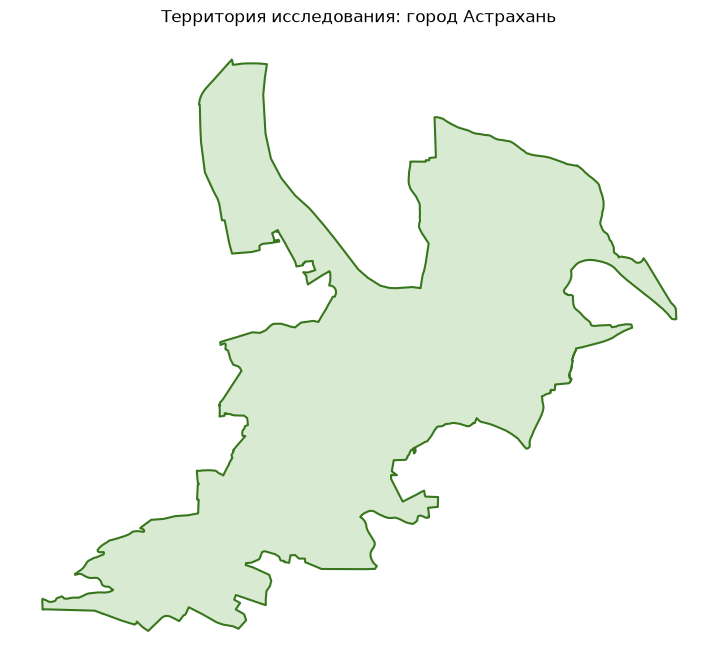

In [65]:
ax = boundaries.plot(color="#d9ead3", edgecolor="#38761d", linewidth=1.5, figsize=(9, 9))
ax.set_title("Территория исследования: город Астрахань")
ax.set_axis_off()
plt.show()


## 3. Данные OpenStreetMap и кварталы

### 3.1. Загрузка дорог, железных дорог и воды

Набор тегов повторяет пример `pipeline.ipynb`. Скачиваются только объекты внутри границы города. Каждый слой сохраняется в отдельный GeoJSON, поэтому при повторном запуске скачивание не повторяется.

Вместо перегруженного Overpass API используется официальная выгрузка OpenStreetMap с Geofabrik: файл `south-fed-district-latest.osm.pbf` (~316 МБ) скачивается один раз, после чего все слои читаются из него локально. Это надёжнее и не зависит от доступности Overpass.

Важно: первое скачивание может занять несколько минут. Если оно прервётся, запустите ячейку снова — файл скачается заново (незавершённый `.part` не используется).


In [66]:
bc_tags = {
    "roads": {
        "highway": [
            "construction", "crossing", "living_street", "motorway", "motorway_link",
            "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
            "residential", "road", "secondary", "secondary_link", "services", "tertiary",
            "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
            "turning_loop", "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}


In [67]:
import re
import requests

OSM_PBF_URL = "https://download.geofabrik.de/russia/south-fed-district-latest.osm.pbf"
OSM_PBF_NAME = "south-fed-district-latest.osm.pbf"
PBF_CACHE = {}
OTHER_TAGS_PATTERN = re.compile(r'"([^"]+)"=>"([^"]*)"')


def ensure_pbf():
    path = file_path(OSM_PBF_NAME)
    if path.exists():
        print(f"{OSM_PBF_NAME}: использую скачанный файл")
        return path

    print(f"Скачиваю {OSM_PBF_NAME} (~316 МБ, один раз)...")
    tmp = path.with_suffix(".part")
    with requests.get(OSM_PBF_URL, stream=True, timeout=120) as response:
        response.raise_for_status()
        total = int(response.headers.get("content-length", 0))
        downloaded = 0
        with open(tmp, "wb") as handle:
            for chunk in response.iter_content(chunk_size=4 * 1024 * 1024):
                if not chunk:
                    continue
                handle.write(chunk)
                downloaded += len(chunk)
                if total:
                    percent = downloaded / total * 100
                    print(
                        f"\r  {percent:5.1f}%  {downloaded / 1024 / 1024:.0f} / "
                        f"{total / 1024 / 1024:.0f} МБ",
                        end="",
                    )
    print()
    tmp.replace(path)
    return path


def pbf_layer(layer):
    if layer in PBF_CACHE:
        return PBF_CACHE[layer]

    bbox = tuple(boundaries.to_crs(4326).total_bounds)
    print(f"{layer}: читаю из {OSM_PBF_NAME}...")
    gdf = gpd.read_file(ensure_pbf(), layer=layer, bbox=bbox, engine="pyogrio")
    gdf = gdf.to_crs(crs)
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()
    PBF_CACHE[layer] = gdf
    print(f"  {layer}: {len(gdf)} объектов")
    return gdf


def parse_other_tags(value):
    if not isinstance(value, str) or not value:
        return {}
    return dict(OTHER_TAGS_PATTERN.findall(value))


def add_tags(gdf, keys):
    gdf = gdf.copy()
    parsed = gdf["other_tags"].map(parse_other_tags)
    for key in keys:
        values = parsed.map(lambda tags: tags.get(key))
        if key in gdf.columns:
            gdf[key] = gdf[key].where(gdf[key].notna(), values)
        else:
            gdf[key] = values
    return gdf


def clip_to_boundary(gdf, geometry_types):
    gdf = gdf[
        gdf.geometry.notna() & ~gdf.geometry.is_empty & gdf.geometry.is_valid
    ].copy()
    if len(gdf):
        gdf = gpd.clip(gdf, boundaries)
    gdf = gdf[gdf.geom_type.isin(geometry_types)]
    return gdf.reset_index(drop=True)


def _cache(name, builder, geometry_types):
    if exists(name):
        gdf = read_gdf(name)
        if gdf.geometry.geom_type.isin(geometry_types).all():
            return gdf
        print(f"{name}: в сохранённом файле неверная геометрия, пересобираю")

    gdf = clip_to_boundary(builder(), geometry_types)
    write_gdf(gdf, name)
    return gdf


def filter_roads():
    lines = pbf_layer("lines")
    return lines[lines["highway"].isin(bc_tags["roads"]["highway"])][["geometry"]].copy()


def filter_railways():
    lines = pbf_layer("lines")
    return lines[lines["railway"] == "rail"][["geometry"]].copy()


def filter_water():
    lines = pbf_layer("lines")
    polygons = add_tags(pbf_layer("multipolygons"), ["waterway", "water"])
    water_lines = lines[lines["waterway"].isin(["river", "canal", "ditch"])][["geometry"]]
    mask = (
        polygons["natural"].isin(["water", "bay"])
        | polygons["landuse"].eq("basin")
        | polygons["water"].isin(["riverbank", "lake", "reservoir", "basin", "canal", "pond", "dock"])
        | polygons["waterway"].isin(["riverbank", "canal", "river", "ditch"])
        | polygons["other_tags"].fillna("").str.contains('"riverbank"=>"yes"', regex=False)
    )
    water_polygons = polygons[mask][["geometry"]]
    return pd.concat([water_lines, water_polygons], ignore_index=True)


def filter_landuse():
    polygons = pbf_layer("multipolygons")
    result = polygons[polygons["landuse"].notna()][["geometry", "landuse"]].copy()
    return result.rename(columns={"landuse": "functional_zone"})


def filter_buildings():
    polygons = add_tags(pbf_layer("multipolygons"), ["building:levels"])
    tag_columns = [
        "osm_way_id", "building", "building:levels",
        "amenity", "shop", "office", "tourism", "leisure", "man_made",
    ]
    columns = ["geometry"] + [c for c in tag_columns if c in polygons.columns]
    result = polygons[polygons["building"].notna()][columns].copy()
    return clip_to_boundary(result, ["Polygon", "MultiPolygon"])


def filter_services(tags_list):
    points = add_tags(
        pbf_layer("points"),
        ["amenity", "healthcare", "beds", "capacity", "capacity:patients"],
    )
    polygons = add_tags(
        pbf_layer("multipolygons"),
        ["healthcare", "beds", "capacity", "capacity:patients"],
    )

    frames = []
    for tags in tags_list:
        for source in (points, polygons):
            mask = pd.Series(True, index=source.index)
            for key, wanted in tags.items():
                if key not in source.columns:
                    mask[:] = False
                    break
                wanted_values = [wanted] if isinstance(wanted, str) else list(wanted)
                mask &= source[key].isin(wanted_values)
            part = source[mask]
            if len(part):
                frames.append(part)

    if not frames:
        raise ValueError("в PBF не найдено объектов услуг")

    result = pd.concat(frames, ignore_index=True)
    result = result.drop_duplicates(subset="geometry").reset_index(drop=True)

    is_polygon = result.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
    polygons = result[is_polygon]
    points = result[~is_polygon]
    if len(polygons) and len(points):
        covered = polygons.geometry.buffer(50).union_all()
        points = points[~points.within(covered)]
    result = pd.concat([polygons, points], ignore_index=True).reset_index(drop=True)

    capacity = result["capacity"].copy()
    for column in ["beds", "capacity:patients"]:
        if column in result.columns:
            capacity = capacity.fillna(result[column])
    result["capacity"] = pd.to_numeric(capacity, errors="coerce")
    keep = [c for c in ["name", "capacity", "geometry"] if c in result.columns]
    return clip_to_boundary(
        result[keep].copy(), ["Point", "MultiPoint", "Polygon", "MultiPolygon"]
    )


roads = _cache("roads.geojson", filter_roads, ["LineString", "MultiLineString"])
railways = _cache("railways.geojson", filter_railways, ["LineString", "MultiLineString"])
water = _cache(
    "water.geojson",
    filter_water,
    ["Polygon", "MultiPolygon", "LineString", "MultiLineString"],
)

print("Дорог:", len(roads))
print("Железных дорог:", len(railways))
print("Водных объектов:", len(water))


roads.geojson: читаю готовый файл
railways.geojson: читаю готовый файл
water.geojson: читаю готовый файл
Дорог: 5365
Железных дорог: 617
Водных объектов: 94


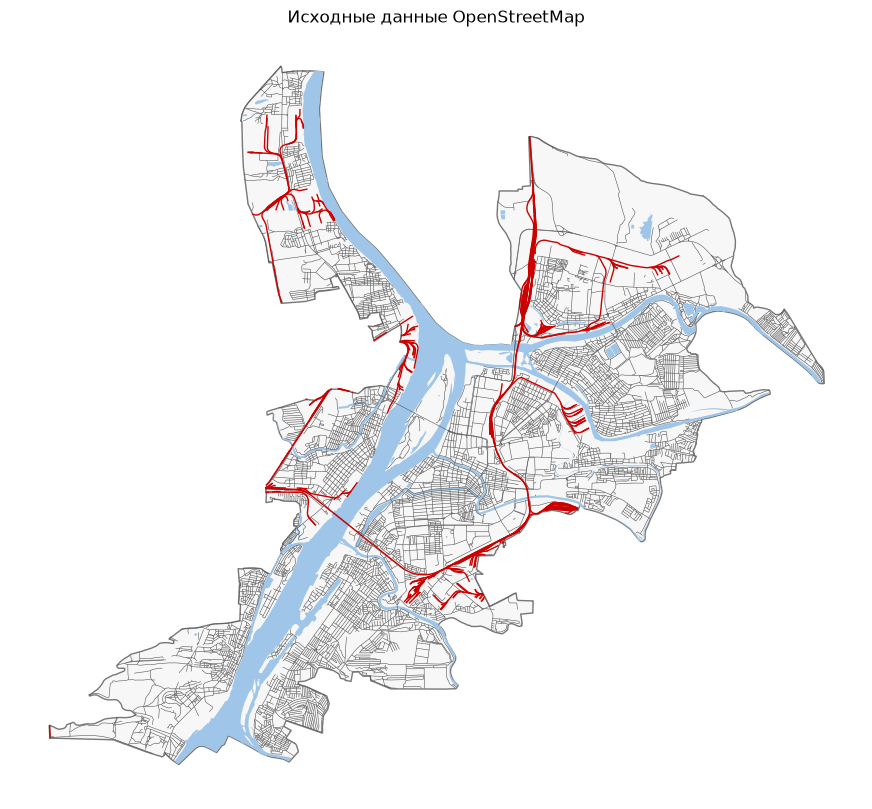

In [68]:
fig, ax = plt.subplots(figsize=(11, 11))
boundaries.plot(ax=ax, color="#f7f7f7", edgecolor="#777777", linewidth=1)
water.plot(ax=ax, color="#9fc5e8", edgecolor="none")
roads.plot(ax=ax, color="#555555", linewidth=0.4)
railways.plot(ax=ax, color="#cc0000", linewidth=1)
ax.set_title("Исходные данные OpenStreetMap")
ax.set_axis_off()
plt.show()


### 3.2. Нарезка кварталов

`preprocess_urban_objects` приводит линии и полигоны к единой схеме, а `cut_urban_blocks` режет территорию по дорогам, железным дорогам и воде. Получаются замкнутые городские кварталы.

Результат сохраняется в `blocks_raw.geojson`.


In [69]:
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects

if exists("blocks_raw.geojson"):
    blocks = read_gdf("blocks_raw.geojson")
else:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons)
    write_gdf(blocks, "blocks_raw.geojson")

print("Кварталов:", len(blocks))
print("Средняя площадь квартала, га:", round(blocks.area.mean() / 10_000, 2))


blocks_raw.geojson: читаю готовый файл
Кварталов: 4441
Средняя площадь квартала, га: 4.08


### 3.3. Назначение территории (land use)

Скачиваем полигоны `landuse` из OpenStreetMap и переводим их в категории BlocksNet по словарю `rules`. Если для квартала не нашлось подходящей зоны, останется «нет данных» (None).

Результат сохраняется в `blocks.geojson`. Если вы хотите изменить правила, удалите `blocks.geojson` или включите `FORCE_RECALC`.


In [70]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

rules = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
    "governmental": LandUse.SPECIAL,
    "farmyard": LandUse.AGRICULTURE,
    "allotments": LandUse.AGRICULTURE,
    "harbour": LandUse.TRANSPORT,
    "village_green": LandUse.RECREATION,
    "meadow": LandUse.AGRICULTURE,
    "railway": LandUse.TRANSPORT,
}

if exists("blocks.geojson"):
    blocks = read_gdf("blocks.geojson")
else:
    functional_zones = _cache(
        "functional_zones.geojson", filter_landuse, ["Polygon", "MultiPolygon"]
    )
    blocks = assign_land_use(blocks, functional_zones, rules)
    blocks["land_use"] = blocks["land_use"].apply(
        lambda value: value.value if hasattr(value, "value") else value
    )
    write_gdf(blocks, "blocks.geojson")

print("Кварталов с назначением территории:", len(blocks))
print(blocks["land_use"].fillna("нет данных").value_counts(dropna=False).to_string())


blocks.geojson: читаю готовый файл
Кварталов с назначением территории: 4441
land_use
нет данных     2777
residential    1116
agriculture     221
transport       105
industrial       85
recreation       69
business         51
special          17


### 3.4. Карта кварталов и назначения территории

На карте серым показаны кварталы, для которых в OSM не нашлось назначения территории. Это не пропущенные кварталы, а отсутствие данных land use: геометрия кварталов построена полностью.


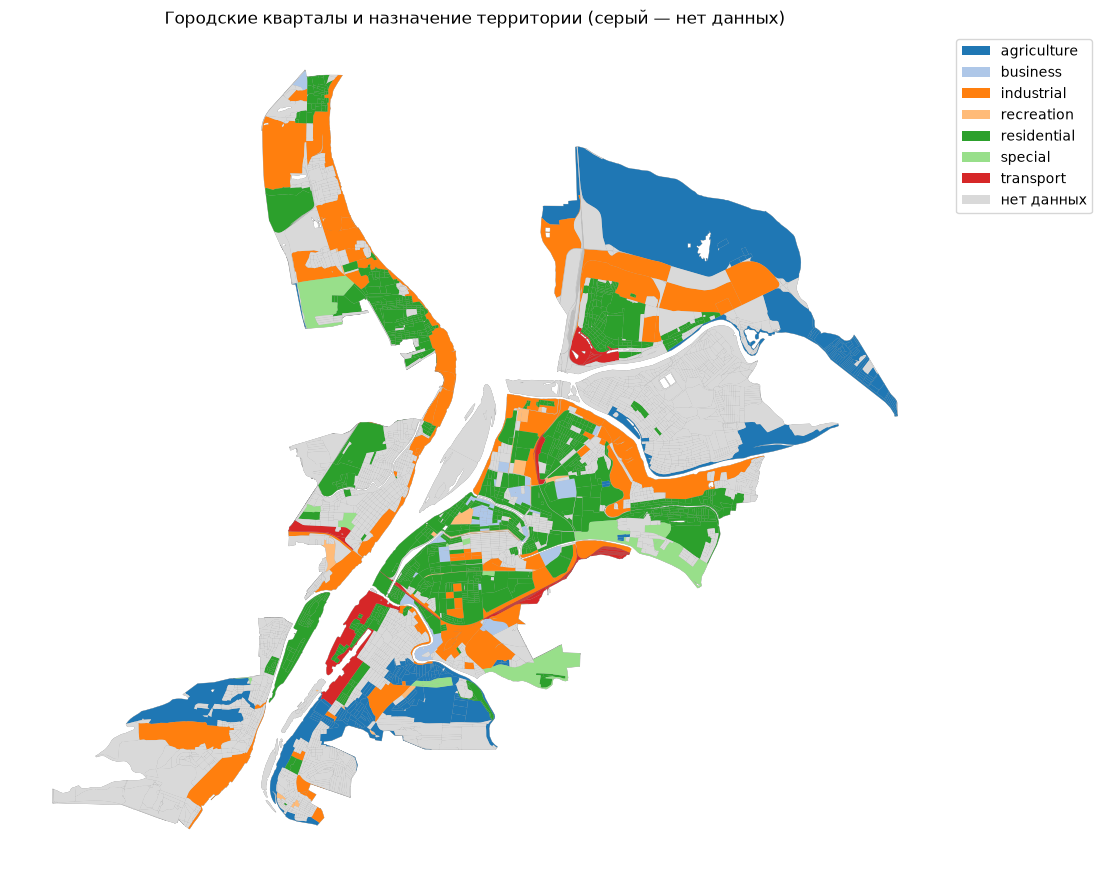

In [71]:
fig, ax = plt.subplots(figsize=(12, 12))
blocks.plot(ax=ax, color="#e6e6e6", edgecolor="#888888", linewidth=0.3)
blocks.plot(
    column="land_use",
    ax=ax,
    legend=True,
    cmap="tab20",
    categorical=True,
    missing_kwds={"color": "#d9d9d9", "label": "нет данных"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1)},
)
ax.set_title("Городские кварталы и назначение территории (серый — нет данных)")
ax.set_axis_off()
plt.show()


### 3.5. Словарь метрик: что умеет BlocksNet и что посчитаем мы

Все метрики считаются **по кварталам** — это минимальные территории, на которые мы нарезали город. У каждой метрики есть своя единица измерения, поэтому сначала договоримся о базовых:

- площадь — квадратные метры (м²); в выводах удобно переводить в гектары: 1 га = 10 000 м²;
- время — минуты пешком;
- доли и индексы — обычно от 0 до 1, если не указано иное;
- население — человек;
- ёмкость услуг — места, койки или посещения в смену (зависит от типа услуги).

Главная идея: BlocksNet не говорит «хорошо» или «плохо». Он считает измеримые характеристики территории, а мы уже интерпретируем их для Астрахани.

#### 1. Какие группы метрик есть в BlocksNet

**Геометрия квартала**

- `site_area` — площадь квартала, м². Самый базовый показатель: на него делятся все плотности.
- `site_length` — периметр квартала, м. Помогает понять, насколько квартал компактный.
- `outer_radius` — радиус минимальной окружности, которая охватывает квартал, м.
- `inner_radius` — радиус самой большой окружности, которую можно вписать в квартал, м. Вместе с `outer_radius` показывает вытянутость и «дырявость» формы.
- `aspect_ratio` — отношение длинной стороны квартала к короткой, безразмерное. 1 — почти квадрат, 5 — очень вытянутый квартал.
- `centerline_length` — длина осевой линии квартала, м. Вспомогательная характеристика формы.

**Застройка и плотность**

- `population` — расчётное население квартала, человек.
- `footprint_area` — площадь пятна застройки, м². Это площадь земли, которую занимают здания сверху.
- `build_floor_area` — суммарная поэтажная площадь зданий, м². Если дом 10 × 10 м и 5 этажей, его вклад примерно 500 м².
- `living_area` — жилая площадь, м².
- `non_living_area` — нежилая площадь, м².
- `number_of_floors` — сумма этажей зданий квартала. Это не средняя этажность; средняя этажность считается через `l`.
- `is_living` — в агрегированной таблице это число жилых зданий (флаг «жилое» суммируется), а не доля.
- `fsi` (Floor Space Index) — сколько квадратных метров всех этажей приходится на 1 м² квартала. Безразмерный, может быть больше 1. Простыми словами: «насколько плотно застроен квартал по вертикали и горизонтали вместе».
- `gsi` (Ground Space Index) — какая доля квартала занята зданиями сверху, от 0 до 1. Простыми словами: «насколько квартал застроен, а не занят дворами, дорогами и зеленью».
- `mxi` (Mix Index) — какая доля общей поэтажной площади является жилой, от 0 до 1. 0 — совсем нежилой квартал, 1 — полностью жилой.
- `l` — средняя этажность: общая поэтажная площадь делится на площадь пятна застройки. Единица — этажи.
- `osr` (Open Space Ratio) — сколько открытой площади (дворы, проходы, зелень) приходится на 1 м² общей поэтажной площади. Безразмерный. Чем выше, тем «просторнее» квартал при той же этажности.
- `share_living` — жилая площадь на 1 м² пятна застройки. Безразмерная, может быть больше 1.
- `share_non_living` — нежилая площадь на 1 м² пятна застройки. Безразмерная.

**Морфотипы застройки**

- Spacematrix — автоматическая кластеризация кварталов по трём показателям: этажность `l`, плотность `fsi`, доля жилья `mxi`. Результат: номер кластера `cluster` (0–10) и текстовый `morphotype`, например «high-rise residential high-density».
- Strelka — морфотипы по правилам, без кластеризации: низкая/средняя/высокая этажность, жилой/нежилой/смешанный, микрорайон/квартал/центральная модель. Результат — текстовый `morphotype`.
- Оба показателя категориальные: у них нет единицы измерения, это «тип квартала».

**Пешеходная доступность**

- `accessibility_matrix` — таблица «квартал × квартал» со временем в пути между центрами кварталов, минуты.
- `mean_accessibility`, `median_accessibility`, `max_accessibility` — среднее, медиана и максимум времени до всех кварталов, минуты.
- `area_accessibility` — средневзвешенное время до всех кварталов, где вес — площадь квартала назначения. Минуты. Простыми словами: «насколько квартал удобно расположен относительно всего города». Чем меньше, тем лучше.
- `land_use_accessibility` — медианное время до кварталов с определённым назначением (например, до всех жилых или всех рабочих мест), минуты.
- `connectivity` — величина, обратная доступности: 1 / время. Чем выше, тем связнее квартал. Единица — 1/мин.

**Услуги и обеспеченность**

- `services_count` — количество объектов услуги в квартале, штук.
- `services_density` — количество объектов на 1 м² площади квартала. На практике удобнее умножать на 10 000 и читать как «объектов на гектар».
- `services_collocation` — matriz сходства: как часто разные услуги встречаются в одних и тех же кварталах. Значение от 0 до 1.
- `shannon_diversity` — разнообразие типов услуг, в натах (логарифмическая шкала). 0 — услуг нет или все одного типа; чем выше, тем разнообразнее набор.
- `competitive_provision` — распределение спроса между услугами с учётом конкуренции и времени в пути.
- `provision_strong` — доля спроса, покрытая услугами **в пределах норматива доступности**, от 0 до 1. Главный показатель обеспеченности.
- `provision_weak` — доля спроса, покрытая услугами **вообще**, даже если до них дольше норматива, от 0 до 1. При расчёте с `max_depth=1` совпадает с `provision_strong`; разница появляется, если разрешить искать услуги за пределами норматива.
- `demand` — нормативная потребность, человек или единиц спроса.
- `capacity` — ёмкость услуг, места/койки/посещения.
- `demand_within`, `demand_without`, `demand_left`, `capacity_within`, `capacity_without`, `capacity_left` — расшифровка баланса: сколько спроса покрыто в норме, сколько вне нормы, сколько осталось; сколько ёмкости использовано и осталось.
- `links_df` — таблица связей «откуда → куда → сколько людей/единиц спроса», помогает увидеть, жители каких кварталов ездят в какую больницу или поликлинику.

**Центральность**

- `population_centrality` — композитный индекс 0–1: сочетание численности населения и связности квартала с соседями. Показывает «людные и связанные» места.
- `services_centrality` — композитный индекс 0–1: сочетание связности, разнообразия и плотности услуг. Показывает центры обслуживания.

**Назначение территории (land use)**

- `calculate_land_use_shares` — доли площади города по категориям (жилая, деловая, промышленная, рекреационная и т. д.), от 0 до 1.
- `land_use_collocation` — насколько соседние кварталы совместимы по назначению, от 0 до 1.
- `land_use_similarity` — подбор наиболее вероятного назначения квартала по набору услуг, с вероятностью от 0 до 1.
- `get_vacant_areas` — свободные от застройки участки внутри кварталов, площадь в м². Потенциальные резервы территории.

**Транспорт и социально-экономический блок**

- `origin_destination_matrix` — условная матрица поездок между узлами сети; это не официальная статистика поездок, а модельная оценка притяжения.
- `road_congestion` — распределение модельного потока по рёбрам графа; показывает потенциально перегруженные участки.
- В BlocksNet есть отдельный блок социально-экономических индикаторов: демография, социальная инфраструктура, экономика, экология, инженерия, транспорт, расселение. В этом учебном сценарии мы его не используем, чтобы не перегружать ноутбук.

#### 2. Все показатели из `pipeline.ipynb`

В примере `pipeline.ipynb` рассчитываются следующие вещи. Мы сохраняем ту же логику, но вместо школ подставляем больницы и поликлиники.

**Агрегация зданий по кварталам**

| Показатель | Единица | Что означает |
|---|---|---|
| `population` | человек | Расчётное население квартала |
| `footprint_area` | м² | Площадь пятна застройки |
| `build_floor_area` | м² | Суммарная поэтажная площадь |
| `living_area` | м² | Жилая площадь |
| `non_living_area` | м² | Нежилая площадь |
| `number_of_floors` | этажи (сумма) | Сумма этажей всех зданий; не средняя этажность |
| `is_living` | штуки (сумма флагов) | Число жилых зданий в квартале |

**Плотностные показатели (`calculate_density_indicators`)**

| Показатель | Единица | Что означает |
|---|---|---|
| `fsi` | м² / м², безразмерный | Поэтажная площадь на площадь квартала |
| `gsi` | 0–1 | Доля квартала под зданиями |
| `mxi` | 0–1 | Доля жилой площади в общей поэтажной |
| `l` | этажи | Средняя этажность застройки |
| `osr` | м² / м², безразмерный | Открытая площадь на поэтажную площадь |
| `share_living` | м² / м², безразмерный | Жилая площадь на площадь пятна застройки |
| `share_non_living` | м² / м², безразмерный | Нежилая площадь на площадь пятна застройки |

**Морфотипы (`get_spacematrix_morphotypes`, `get_strelka_morphotypes`)**

| Показатель | Единица | Что означает |
|---|---|---|
| `cluster` | 0–10, категория | Номер кластера Spacematrix |
| `morphotype` (Spacematrix) | текст, категория | Тип квартала по этажности, плотности и доле жилья |
| `spacematrix_clusters` | таблица | Центры кластеров и их расшифровка; не по кварталам, а по типам |
| `morphotype` (Strelka) | текст, категория | Тип квартала по правилам Strelka |

**Доступность (`accessibility_matrix`, `area_accessibility`)**

| Показатель | Единица | Что означает |
|---|---|---|
| `accessibility_matrix` | минуты | Время пешком между каждой парой кварталов |
| `area_accessibility` | минуты | Средневзвешенное время до всех кварталов, вес — площадь квартала |

**Обеспеченность (`competitive_provision`)**

| Показатель | Единица | Что означает |
|---|---|---|
| `demand` | человек / единицы спроса | Нормативная потребность |
| `capacity` | места / койки / посещения | Ёмкость услуг |
| `provision_strong` | 0–1 | Доля спроса, покрытая в пределах норматива |
| `provision_weak` | 0–1 | Доля спроса, покрытая с учётом объектов за нормативом |
| `demand_within` | человек / единицы | Спрос, покрытый в норме |
| `demand_without` | человек / единицы | Спрос, покрытый вне нормы |
| `demand_left` | человек / единицы | Непокрытый спрос |
| `capacity_within` | места / койки | Использованная ёмкость в норме |
| `capacity_without` | места / койки | Использованная ёмкость вне нормы |
| `capacity_left` | места / койки | Остаток ёмкости |
| `links_df` (`source`, `target`, `value`) | человек / единицы | Сколько спроса из квартала-источника направлено в квартал-услугу |

**Агрегация услуг**

| Показатель | Единица | Что означает |
|---|---|---|
| `count` | штуки | Число объектов услуги в квартале |
| `capacity` | места / койки / посещения | Суммарная ёмкость объектов услуги |

#### 3. Что это расскажет об Астрахани

- **Плотность и этажность (`fsi`, `gsi`, `l`, `osr`)** — где город застроен плотно, а где рыхло; где исторический центр с высокой долей застройки, а где частный сектор и окраины. Это помогает увидеть, насколько Астрахань моноцентрична.
- **Доля жилья (`mxi`, `share_living`)** — где кварталы преимущественно жилые, а где деловые, промышленные или рекреационные. Полезно для проверки, не переоценили ли мы население в нежилых районах.
- **Морфотипы** — типология городской ткани: частная низкая застройка, советские микрорайоны, современные высотные комплексы, нежилые промышленные зоны. Это удобная рамка для сравнения районов.
- **Пешеходная доступность (`area_accessibility`)** — какие кварталы «включены» в город пешком, а какие изолированы рекой, железной дорогой или промышленной зоной. Низкая доступность на окраинах — не обязательно плохо, но это важный контекст для обеспеченности.
- **Обеспеченность (`provision_strong`)** — где жителям не хватает больниц в пределах 60 минут и поликлиник в пределах 15 минут. Это главный практический результат: дефицит видно по кварталам, а не только по городу в среднем.
- **`provision_weak` и `links_df`** — позволяют отличить «формально услуга есть, но далеко» от «услуги рядом нет вообще» и увидеть, куда направляются потоки жителей.
- **Назначение территории** — сколько площади занято жильём, промышленностью, сельским хозяйством, рекреацией; где находятся деловые и общественные центры.

#### 4. Что считаем в этом ноутбуке, а что оставляем за рамками

В ноутбуке уже предусмотрены:

- матрица пешеходной доступности;
- население и агрегация зданий;
- больницы и поликлиники, их ёмкость и обеспеченность `provision_strong`;
- плотностные показатели `fsi`, `gsi`, `mxi`, `l`, `osr`, `share_living`, `share_non_living`;
- морфотипы Spacematrix и Strelka;
- `area_accessibility`;
- доли land use как описательная характеристика.

За рамками учебного сценария оставляем:

- платные и неполные данные о населении (используем модель по этажности и нормативу 30 м²/чел.);
- общественный транспорт и автомобильный граф (считаем только пешком);
- социально-экономические индикаторы BlocksNet;
- прогнозирование land use и оптимизацию размещения услуг.

**Важно помнить об ограничениях.** OSM неполон: у 62% кварталов нет полигона land use, а ёмкость больниц и поликлиник часто отсутствует и заменяется минимальным значением из справочника. Поэтому результаты — это оценка на основе открытых данных, а не официальная статистика. Все выводы нужно формулировать как «по данным OSM и модели BlocksNet», а не как окончательный факт.


## 4. СТОП: согласование метрик

**Дальше не запускайте, пока не посмотрите кварталы.**

Проверьте:

- кварталы покрывают всю территорию и не содержат явных ошибок;
- назначение территории выглядит правдоподобно;
- число кварталов и их размеры подходят для исследования.

Полный словарь метрик и единиц измерения — в разделе 3.5. После этого согласуем список показателей: в ноутбуке уже предусмотрены пешеходная доступность, население, обеспеченность больницами и поликлиниками, плотность, морфотипы Spacematrix и Strelka.

Если нужно изменить состав услуг или правила land use — это делается до раздела 5.


In [72]:
print("ОСТАНОВКА: разделы ниже запускаются только после согласования метрик.")
print("Сейчас подготовлено кварталов:", len(blocks))


ОСТАНОВКА: разделы ниже запускаются только после согласования метрик.
Сейчас подготовлено кварталов: 4441


## 5. Пешеходный граф и матрица доступности

### 5.1. Граф

Выбран **пешеходный граф** (`walk`), потому что он:

- не требует расписаний общественного транспорта;
- покрывает все кварталы, включая территории без дорог для автомобилей;
- даёт устойчивую оценку «пешком за N минут».

Источник — OpenStreetMap, пешеходная сеть. Скорость по умолчанию 5 км/ч (83.33 м/мин), время в минутах хранится в атрибуте ребра `time_min`.

Граф сохраняется в `walk_graph.graphml`.

Примечание: библиотека строит граф по выпуклой оболочке границы, поэтому он немного больше самого города.


In [73]:
from blocksnet.relations import get_accessibility_graph

if exists("walk_graph.graphml"):
    graph = read_graph("walk_graph.graphml")
else:
    graph = get_accessibility_graph(boundaries, "walk")
    write_graph(graph, "walk_graph.graphml")

print("Узлов графа:", graph.number_of_nodes())
print("Рёбер графа:", graph.number_of_edges())


walk_graph.graphml: читаю готовый граф
Узлов графа: 21052
Рёбер графа: 62014


### 5.2. Матрица времени в пути

`calculate_accessibility_matrix` считает кратчайшее время между центрами всех кварталов. Результат — квадратная матрица `n × n`, где `n` — число кварталов. Единица измерения — **минуты**, потому что используется вес `time_min`.

Матрица сохраняется в `accessibility_matrix.csv`. Расчёт может занять несколько минут.

На графике ниже показаны все пары без обрезки; красная линия — 120 минут.

In [74]:
from blocksnet.relations import calculate_accessibility_matrix

if exists("accessibility_matrix.csv"):
    acc_mx = read_csv("accessibility_matrix.csv")
    try:
        acc_mx.columns = acc_mx.columns.astype(int)
    except (TypeError, ValueError):
        pass
else:
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    write_csv(acc_mx, "accessibility_matrix.csv")

print("Размер матрицы:", acc_mx.shape)
acc_mx.iloc[:5, :5]


accessibility_matrix.csv: читаю готовый файл
Размер матрицы: (4441, 4441)


,0,1,2,3,4
0,0.000,2.410,7.110,12.375,10.766
1,2.410,0.000,8.310,13.586,11.970
2,7.110,8.310,0.000,5.500,3.883
3,12.375,13.586,5.500,0.000,3.512
4,10.766,11.970,3.883,3.512,0.000


Доля пар кварталов без маршрута: 0.0 %
Время в пути, минуты:
count    19718040.00
mean          136.50
std            70.07
min             0.00
25%            82.94
50%           131.00
75%           183.60
max           460.50
Доля пар дольше 120 минут: 55.7%


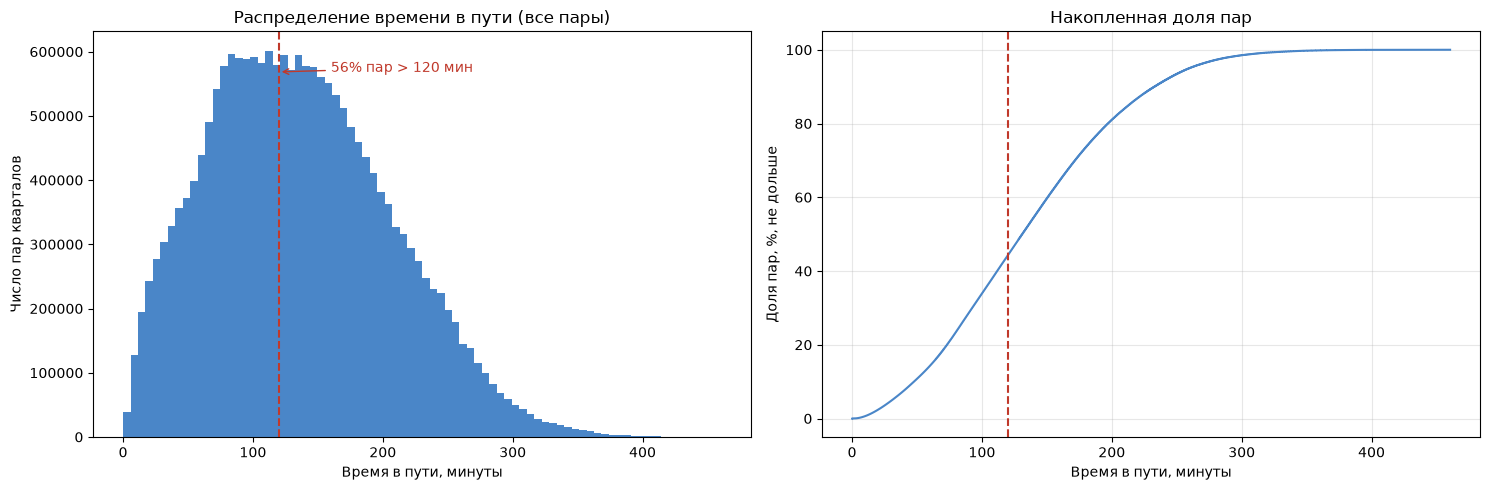

In [75]:
matrix_values = acc_mx.to_numpy(dtype="float64", copy=True)
off_diagonal = ~np.eye(acc_mx.shape[0], dtype=bool)
matrix_values = matrix_values[off_diagonal]
finite_values = matrix_values[np.isfinite(matrix_values)]
travel = pd.Series(finite_values)

share_over_120 = float((travel > 120).mean() * 100)

print("Доля пар кварталов без маршрута:", round(float((~np.isfinite(matrix_values)).mean() * 100), 2), "%")
print("Время в пути, минуты:")
print(travel.describe().round(2).to_string())
print(f"Доля пар дольше 120 минут: {share_over_120:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(travel, bins=80, color="#4a86c8")
axes[0].axvline(120, color="#c0392b", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Время в пути, минуты")
axes[0].set_ylabel("Число пар кварталов")
axes[0].set_title("Распределение времени в пути (все пары)")
axes[0].annotate(
    f"{share_over_120:.0f}% пар > 120 мин",
    xy=(120, axes[0].get_ylim()[1] * 0.9),
    xytext=(160, axes[0].get_ylim()[1] * 0.9),
    color="#c0392b",
    arrowprops=dict(arrowstyle="->", color="#c0392b"),
)

sorted_values = np.sort(finite_values)
cdf = np.arange(1, len(sorted_values) + 1) / len(sorted_values) * 100
axes[1].plot(sorted_values, cdf, color="#4a86c8")
axes[1].axvline(120, color="#c0392b", linestyle="--", linewidth=1.5)
axes[1].set_xlabel("Время в пути, минуты")
axes[1].set_ylabel("Доля пар, %, не дольше")
axes[1].set_title("Накопленная доля пар")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Здания и население

Скачиваем здания из OpenStreetMap. Для каждого здания определяем:

- `is_living` — жилое ли оно;
- `number_of_floors` — этажность из тега `building:levels`.

Пропуски заполняет `impute_buildings`: площадь застройки, площадь этажей, жилая и нежилая площадь, население. Затем `aggregate_objects` суммирует показатели внутри каждого квартала.

Сырое `population` из BlocksNet — не абсолютная численность, а пространственный прокси. Оно зависит от допущений модели: 30 м² на человека, этажность, тег `building=yes`. Поэтому в разделе считаются два показателя:

- `population` — модельная оценка до калибровки;
- `population_calibrated` — официальная численность, распределённая по кварталам пропорционально жилой площади.

Официальная численность для калибровки: **465 990 человек** (Росстат / администрация, 2025). Вес — `living_area`; если жилая площадь везде нулевая, используется `footprint_area * number_of_floors`.

Нулевое значение означает, что в квартале нет жилой застройки или модель не нашла населения. Это не пропуск данных: на карте такие кварталы показаны серым.

В Астрахани многие дома в OSM помечены просто `building=yes`. Если считать жилыми только `residential`, `house`, `apartments` и похожие теги, население занижается в разы. Поэтому `yes` тоже считается жилым, но только если у объекта нет нежилых тегов (`amenity`, `shop`, `office`, `tourism`, `leisure`, `man_made`). Дополнительно вручную исключены два нежилых объекта на острове — OSM way 292110824 («Пост ГИБДД») и 1008406468.

Ограничение: среди `yes` всё равно могут остаться нежилые объекты без тегов; калибровка сохраняет это смещение, поэтому карту стоит проверять по OSM.

Результаты: `buildings.geojson` и `buildings_blocks.geojson`.


In [76]:
from blocksnet.preprocessing.imputing import impute_buildings

IS_LIVING_TAGS = [
    "residential", "house", "apartments", "detached",
    "terrace", "dormitory", "yes",
]
NON_RESIDENTIAL_TAGS = ["amenity", "shop", "office", "tourism", "leisure", "man_made"]
NON_LIVING_OSM_WAY_IDS = {292110824, 1008406468}
MAX_FLOORS = 25


def build_buildings():
    print("buildings: читаю из PBF...")
    buildings = filter_buildings()
    if "osm_way_id" not in buildings.columns:
        raise RuntimeError(
            "filter_buildings() не вернул osm_way_id. "
            "Перезапустите ячейку 10 с обновлённым кодом."
        )

    non_residential_columns = [
        c for c in NON_RESIDENTIAL_TAGS if c in buildings.columns
    ]
    if non_residential_columns:
        non_residential = buildings[non_residential_columns].notna().any(axis=1)
    else:
        non_residential = pd.Series(False, index=buildings.index)

    if "osm_way_id" in buildings.columns:
        manual_exclusion = pd.to_numeric(
            buildings["osm_way_id"], errors="coerce"
        ).isin(NON_LIVING_OSM_WAY_IDS)
    else:
        manual_exclusion = pd.Series(False, index=buildings.index)

    drop = buildings["building"].eq("yes") & (
        non_residential | manual_exclusion
    )
    print("Исключено нежилых building=yes:", int(drop.sum()))
    buildings = buildings[~drop].copy()

    buildings["is_living"] = buildings["building"].isin(IS_LIVING_TAGS)

    if "building:levels" in buildings.columns:
        buildings["number_of_floors"] = pd.to_numeric(
            buildings["building:levels"], errors="coerce"
        )
    else:
        buildings["number_of_floors"] = np.nan

    building_ids = buildings["osm_way_id"].copy()
    too_tall = buildings["number_of_floors"] > MAX_FLOORS
    if too_tall.any():
        print(
            f"Этажность > {MAX_FLOORS} у {int(too_tall.sum())} зданий — заменяю на NaN"
        )
        buildings.loc[too_tall, "number_of_floors"] = np.nan

    buildings = impute_buildings(buildings, default_living_demand=30)
    buildings["osm_way_id"] = building_ids.reindex(buildings.index).to_numpy()

    keep_cols = [
        "geometry", "osm_way_id", "is_living", "number_of_floors",
        "footprint_area", "build_floor_area", "living_area",
        "non_living_area", "population",
    ]
    return buildings[[c for c in keep_cols if c in buildings.columns]].copy()


rebuilt = False
if exists("buildings.geojson"):
    buildings = read_gdf("buildings.geojson")
    floors = pd.to_numeric(buildings["number_of_floors"], errors="coerce")
    needs_rebuild = (
        "osm_way_id" not in buildings.columns
        or floors.gt(MAX_FLOORS).any()
    )
    if needs_rebuild:
        print("Кэш зданий устарел — пересобираю здания из PBF...")
        buildings = build_buildings()
        rebuilt = True
else:
    buildings = build_buildings()
    rebuilt = True

if rebuilt:
    write_gdf(buildings, "buildings.geojson")
    for stale_name in ["buildings_blocks.geojson", "blocks_indicators.geojson"]:
        stale_path = file_path(stale_name)
        if stale_path.exists():
            stale_path.unlink()
            print(f"Удалён устаревший {stale_name} — он будет пересчитан")

print("Зданий:", len(buildings))

suspect_population = buildings["living_area"].fillna(0) / 30
suspect_mask = suspect_population > 2000
suspect = buildings.loc[suspect_mask].assign(
    population_per_building=suspect_population[suspect_mask]
)
print("Зданий с оценкой > 2000 чел.:", len(suspect))
if len(suspect):
    columns = [
        c for c in [
            "number_of_floors", "footprint_area",
            "living_area", "population_per_building",
        ]
        if c in suspect.columns
    ]
    display(
        suspect[columns]
        .sort_values("population_per_building", ascending=False)
        .head(20)
    )


buildings.geojson: читаю готовый файл
Кэш зданий устарел — пересобираю здания из PBF...
buildings: читаю из PBF...
multipolygons: читаю из south-fed-district-latest.osm.pbf...
south-fed-district-latest.osm.pbf: использую скачанный файл


c:\Users\user\Documents\итмо магистратура\СЕМЕСТР 3\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: Non closed ring detected. To avoid accepting it, set the OGR_GEOMETRY_ACCEPT_UNCLOSED_RING configuration option to NO
  return ogr_read(
c:\Users\user\Documents\итмо магистратура\СЕМЕСТР 3\ai-course\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(


  multipolygons: 63612 объектов
Исключено нежилых building=yes: 499
Этажность > 25 у 1 зданий — заменяю на NaN


2026-10-23 08:07:50.526 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-23 08:07:50.659 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-23 08:07:50.683 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-23 08:07:50.683 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-23 08:07:50.715 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


Сохранено: buildings.geojson (47086 объектов)
Удалён устаревший buildings_blocks.geojson — он будет пересчитан
Зданий: 47086
Зданий с оценкой > 2000 чел.: 1


,number_of_floors,footprint_area,living_area,population_per_building
22934,12.0,7120.027546,76896.297495,2563.209916


2026-10-23 08:08:29.643 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-10-23 08:08:29.751 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Сохранено: buildings_blocks.geojson (4441 объектов)


,geometry,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,count,population_calibrated
0,"POLYGON ((268038.842 5128558.071, 268039.893 5...",0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
1,"POLYGON ((268039.893 5128546.417, 268038.842 5...",0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
2,"POLYGON ((267398.494 5128773.896, 267405.562 5...",0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
3,"POLYGON ((267433.087 5128764.044, 267405.562 5...",4.0,4.0,625.157840,625.157840,562.642056,62.515784,16.0,4.0,16.405253
4,"POLYGON ((267480.06 5128748.023, 267433.087 51...",9.0,9.0,1217.544583,1217.544583,1095.790125,121.754458,34.0,9.0,31.950534


Модельная сумма до калибровки: 510208
Официальное население: 465990
Калиброванная сумма: 465990
Кварталов с нулевым населением: 1295
Перцентили калиброванного населения, чел.:
0.50      23
0.75      54
0.90     130
0.95     310
0.99    2018
Максимум: 13762
Топ-10 кварталов:
1015    13761.6
1716    13324.5
883      8943.1
2412     7228.9
3785     6771.3
2150     6519.6
2053     5528.7
822      5349.4
2346     5083.5
1404     5072.9


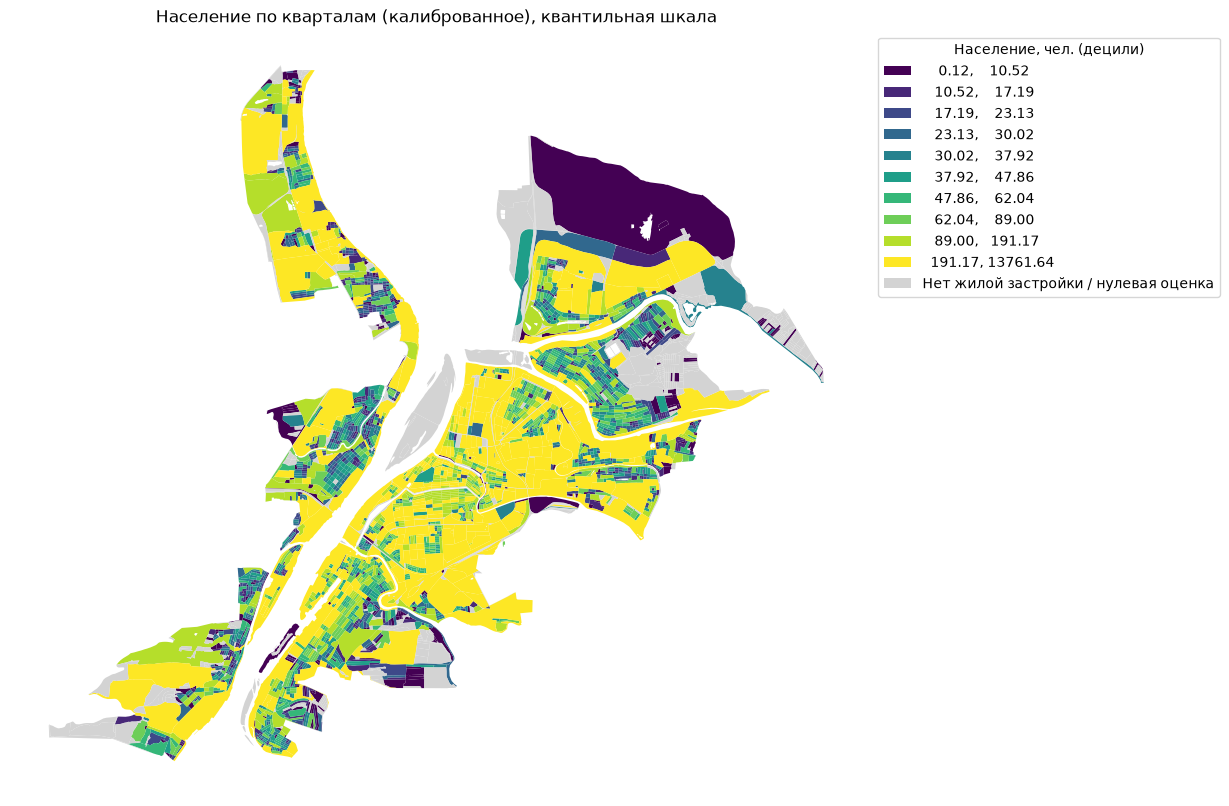

In [77]:
from blocksnet.blocks.aggregation import aggregate_objects

OFFICIAL_POPULATION = 465_990

if exists("buildings_blocks.geojson"):
    buildings_blocks = read_gdf("buildings_blocks.geojson")
else:
    buildings_blocks = aggregate_objects(blocks, buildings)[0]

population = buildings_blocks["population"].fillna(0)
weight = buildings_blocks["living_area"].fillna(0)
if weight.sum() == 0:
    weight = (
        buildings_blocks["footprint_area"].fillna(0)
        * buildings_blocks["number_of_floors"].fillna(1)
    )
if weight.sum() == 0:
    raise ValueError("Нечего использовать как вес: жилая и застроенная площадь нулевые")

buildings_blocks["population_calibrated"] = (
    weight / weight.sum() * OFFICIAL_POPULATION
)
write_gdf(buildings_blocks, "buildings_blocks.geojson")

display(buildings_blocks.head())
print("Модельная сумма до калибровки:", int(population.sum()))
print("Официальное население:", OFFICIAL_POPULATION)
print(
    "Калиброванная сумма:",
    int(round(buildings_blocks["population_calibrated"].sum())),
)
print(
    "Кварталов с нулевым населением:",
    int((buildings_blocks["population_calibrated"] == 0).sum()),
)
print("Перцентили калиброванного населения, чел.:")
print(
    buildings_blocks["population_calibrated"]
    .quantile([0.5, 0.75, 0.9, 0.95, 0.99])
    .round(0)
    .astype(int)
    .to_string()
)
print("Максимум:", int(round(buildings_blocks["population_calibrated"].max())))
print("Топ-10 кварталов:")
print(
    buildings_blocks["population_calibrated"]
    .sort_values(ascending=False)
    .head(10)
    .round(1)
    .to_string()
)

buildings_blocks.assign(
    population_plot=buildings_blocks["population_calibrated"].replace(0, np.nan)
).plot(
    column="population_plot",
    scheme="quantiles",
    k=10,
    cmap="viridis",
    legend=True,
    figsize=(11, 11),
    missing_kwds={
        "color": "lightgrey",
        "label": "Нет жилой застройки / нулевая оценка",
    },
    legend_kwds={
        "title": "Население, чел. (децили)",
        "loc": "upper left",
        "bbox_to_anchor": (1.01, 1),
    },
).set_axis_off()
plt.title("Население по кварталам (калиброванное), квантильная шкала")
plt.show()


### Почему центр на правом берегу выглядит фиолетовым

На линейной шкале цвет зависел от максимального значения. После калибровки максимум — около 13 300 человек. При этом медиана по городу — 22 человека, 75% кварталов — до 53, 90% — до 130. Поэтому кварталы с населением 100–500 человек на фоне максимума выглядят почти фиолетовыми, хотя люди там есть.

Карта выше использует **децили среди кварталов с населением**: каждый цвет — примерно 10% населённых кварталов. Серым показаны кварталы с нулевой оценкой — там нет жилой застройки или модель не нашла населения. Фиолетовый — самые малолюдные кварталы, жёлтый — самые населённые. Это относительная шкала: она показывает, где населения больше или меньше, а не абсолютное число жителей. Абсолютные значения смотрите в таблице перцентилей над картой. Сумма по городу равна 465 990 человек.


## 7. Больницы и поликлиники

Берём два типа услуг из конфигурации BlocksNet:

| Тип | Тег OSM | Норматив (на 1000 чел.) | Доступность |
|---|---|---|---|
| Больница | `amenity=hospital` | 9 | 60 минут |
| Поликлиника | `amenity=clinic`, `healthcare=polyclinic` | 13 | 15 минут |

Ёмкость берётся из OSM, если есть тег `beds` (больницы) или `capacity` (поликлиники). Если тега нет, `impute_services` подставляет минимальную ёмкость из справочника BlocksNet: 110 для больниц и 50 для поликлиник. Для поликлиник это часто занижает реальную ёмкость — отразим это в выводах.

Обеспеченность считается методом `competitive_provision`: спрос распределяется между услугами в пределах норматива доступности.


In [78]:
from blocksnet.preprocessing.imputing import impute_services

def download_services(name, service_type, tags_list):
    if exists(name):
        return read_gdf(name)

    gdf = filter_services(tags_list)
    gdf = impute_services(gdf, service_type)

    keep_cols = [c for c in ["name", "capacity", "geometry"] if c in gdf.columns]
    gdf = gdf[keep_cols].copy()
    write_gdf(gdf, name)
    return gdf


In [79]:
hospitals = download_services("hospitals.geojson", "hospital", [{"amenity": "hospital"}])
print("Больниц:", len(hospitals))
hospitals.head()


points: читаю из south-fed-district-latest.osm.pbf...
south-fed-district-latest.osm.pbf: использую скачанный файл
  points: 10099 объектов
Сохранено: hospitals.geojson (43 объектов)
Больниц: 43


,capacity,geometry
0,110.0,"POLYGON ((264313.375 5130293.701, 264310.657 5..."
1,110.0,"POLYGON ((268418.47 5132521.444, 268378.58 513..."
2,110.0,"POLYGON ((265844.867 5133260.202, 265848.58 51..."
3,110.0,"POLYGON ((268803.926 5133692.886, 268870.884 5..."
4,110.0,"POLYGON ((271904.337 5135837.567, 271965.962 5..."


In [80]:
polyclinics = download_services(
    "polyclinics.geojson",
    "polyclinic",
    [{"amenity": "clinic"}, {"healthcare": "polyclinic"}],
)
print("Поликлиник:", len(polyclinics))
polyclinics.head()


Сохранено: polyclinics.geojson (31 объектов)
Поликлиник: 31


,capacity,geometry
0,50.0,"POLYGON ((266881.625 5130778.766, 266902.425 5..."
1,50.0,"POLYGON ((268341.185 5132447.44, 268298.81 513..."
2,50.0,POINT (273015.915 5134734.659)
3,50.0,POINT (272763.214 5134755.106)
4,50.0,"POLYGON ((270943.103 5135084.831, 270943.606 5..."


In [81]:
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

SERVICE_FILES = [
    "hospitals_blocks.geojson", "hospitals_provision.csv", "hospitals_links.csv",
    "polyclinics_blocks.geojson", "polyclinics_provision.csv", "polyclinics_links.csv",
]


def aggregate_and_assess(services_gdf, service_type, prefix):
    blocks_with_service = aggregate_objects(blocks, services_gdf)[0]

    config = service_types_config[service_type]
    demand = config["demand"]
    accessibility = config["accessibility"]

    population_df = buildings_blocks[["population_calibrated"]].rename(
        columns={"population_calibrated": "population"}
    )
    provision_df, links_df = competitive_provision(
        population_df.join(blocks_with_service[["capacity"]]),
        acc_mx,
        accessibility,
        demand,
    )
    provision_df = provision_df.add_prefix(prefix)
    provision_columns = [f"{prefix}provision_strong", f"{prefix}provision_weak"]
    blocks_with_service = blocks_with_service.join(provision_df[provision_columns])

    print(f"{service_type}: норматив {demand} на 1000 чел., доступность {accessibility} мин")
    print("Кварталов с услугой:", int((blocks_with_service["count"] > 0).sum()))
    return blocks_with_service, provision_df, links_df


if all(exists(name) for name in SERVICE_FILES):
    hospitals_blocks = read_gdf("hospitals_blocks.geojson")
    hospitals_provision = read_csv("hospitals_provision.csv")
    polyclinics_blocks = read_gdf("polyclinics_blocks.geojson")
    polyclinics_provision = read_csv("polyclinics_provision.csv")
    hospitals_links = pd.read_csv(file_path("hospitals_links.csv"), index_col=[0, 1])
    polyclinics_links = pd.read_csv(file_path("polyclinics_links.csv"), index_col=[0, 1])
else:
    hospitals_blocks, hospitals_provision, hospitals_links = aggregate_and_assess(
        hospitals, "hospital", "hospital_"
    )
    polyclinics_blocks, polyclinics_provision, polyclinics_links = aggregate_and_assess(
        polyclinics, "polyclinic", "polyclinic_"
    )

    write_gdf(hospitals_blocks, "hospitals_blocks.geojson")
    write_gdf(polyclinics_blocks, "polyclinics_blocks.geojson")
    write_csv(hospitals_provision, "hospitals_provision.csv")
    write_csv(polyclinics_provision, "polyclinics_provision.csv")
    write_csv(hospitals_links, "hospitals_links.csv")
    write_csv(polyclinics_links, "polyclinics_links.csv")

display(hospitals_blocks[["capacity", "count", "hospital_provision_strong"]].describe().round(2))
display(polyclinics_blocks[["capacity", "count", "polyclinic_provision_strong"]].describe().round(2))


2026-10-23 08:10:03.489 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-23 08:10:03.492 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects
2026-10-23 08:10:03.618 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-23 08:10:03.620 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-23 08:10:03.651 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-23 08:10:03.754 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-23 08:10:12.417 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Pr

hospital: норматив 9 на 1000 чел., доступность 60 мин
Кварталов с услугой: 32


2026-10-23 08:10:12.747 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-23 08:10:14.008 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


polyclinic: норматив 13 на 1000 чел., доступность 15 мин
Кварталов с услугой: 28
Сохранено: hospitals_blocks.geojson (4441 объектов)
Сохранено: polyclinics_blocks.geojson (4441 объектов)
Сохранено: hospitals_provision.csv
Сохранено: polyclinics_provision.csv
Сохранено: hospitals_links.csv
Сохранено: polyclinics_links.csv


,capacity,count,hospital_provision_strong
count,4441.00,4441.00,3146.00
mean,1.07,0.01,0.53
std,13.67,0.12,0.50
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,1.00
75%,0.00,0.00,1.00
max,330.00,3.00,1.00


,capacity,count,polyclinic_provision_strong
count,4441.00,4441.00,3146.00
mean,0.35,0.01,0.04
std,4.67,0.09,0.20
min,0.00,0.00,0.00
25%,0.00,0.00,0.00
50%,0.00,0.00,0.00
75%,0.00,0.00,0.00
max,150.00,3.00,1.00


### 7.1. Проверка баланса обеспеченности

`competitive_provision` возвращает не только `provision_strong` и `provision_weak`, но и полный баланс: сколько спроса и ёмкости покрыто в пределах норматива, сколько осталось. Таблица `links` показывает, из какого квартала в какой направлен спрос. Это те же таблицы, которые в примере выводятся через `prov_df.head()` и `links_df.head()`.


In [85]:
print("Больницы: баланс спроса и ёмкости")
display(hospitals_provision.head())
print("Больницы: связи кварталов")
display(hospitals_links.head())

print("Поликлиники: баланс спроса и ёмкости")
display(polyclinics_provision.head())
print("Поликлиники: связи кварталов")
display(polyclinics_links.head())

print("Агрегация больниц по кварталам")
display(hospitals_blocks.head())
print("Агрегация поликлиник по кварталам")
display(polyclinics_blocks.head())


Больницы: баланс спроса и ёмкости


,hospital_demand,hospital_capacity,hospital_demand_left,hospital_demand_within,hospital_demand_without,hospital_capacity_left,hospital_capacity_within,hospital_capacity_without,hospital_provision_strong,hospital_provision_weak
0,0,0,0,0,0,0,0,0,NaN,NaN
1,0,0,0,0,0,0,0,0,NaN,NaN
2,0,0,0,0,0,0,0,0,NaN,NaN
3,1,0,1,0,0,0,0,0,0.0,0.0
4,1,0,1,0,0,0,0,0,0.0,0.0


Больницы: связи кварталов


,,value
source,target,
21,529,14.0
102,251,6.0
110,251,1.0
113,251,1.0
130,251,1.0


Поликлиники: баланс спроса и ёмкости


...

,,value
source,target,
177,21,3.0
184,21,1.0
197,21,2.0
198,21,2.0
201,21,1.0


Агрегация больниц по кварталам


,geometry,capacity,count,hospital_provision_strong,hospital_provision_weak
0,"POLYGON ((268038.842 5128558.071, 268039.893 5...",0.0,0.0,NaN,NaN
1,"POLYGON ((268039.893 5128546.417, 268038.842 5...",0.0,0.0,NaN,NaN
2,"POLYGON ((267398.494 5128773.896, 267405.562 5...",0.0,0.0,NaN,NaN
3,"POLYGON ((267433.087 5128764.044, 267405.562 5...",0.0,0.0,0.0,0.0
4,"POLYGON ((267480.06 5128748.023, 267433.087 51...",0.0,0.0,0.0,0.0


Агрегация поликлиник по кварталам


,geometry,capacity,count,polyclinic_provision_strong,polyclinic_provision_weak
0,"POLYGON ((268038.842 5128558.071, 268039.893 5...",0.0,0.0,NaN,NaN
1,"POLYGON ((268039.893 5128546.417, 268038.842 5...",0.0,0.0,NaN,NaN
2,"POLYGON ((267398.494 5128773.896, 267405.562 5...",0.0,0.0,NaN,NaN
3,"POLYGON ((267433.087 5128764.044, 267405.562 5...",0.0,0.0,0.0,0.0
4,"POLYGON ((267480.06 5128748.023, 267433.087 51...",0.0,0.0,0.0,0.0


### 7.2. Ёмкость услуг по кварталам

Карта показывает суммарную ёмкость больниц и поликлиник в каждом квартале. Ноль означает, что в квартале нет учреждения этого типа; это не ошибка, а нормальная ситуация для большинства кварталов.


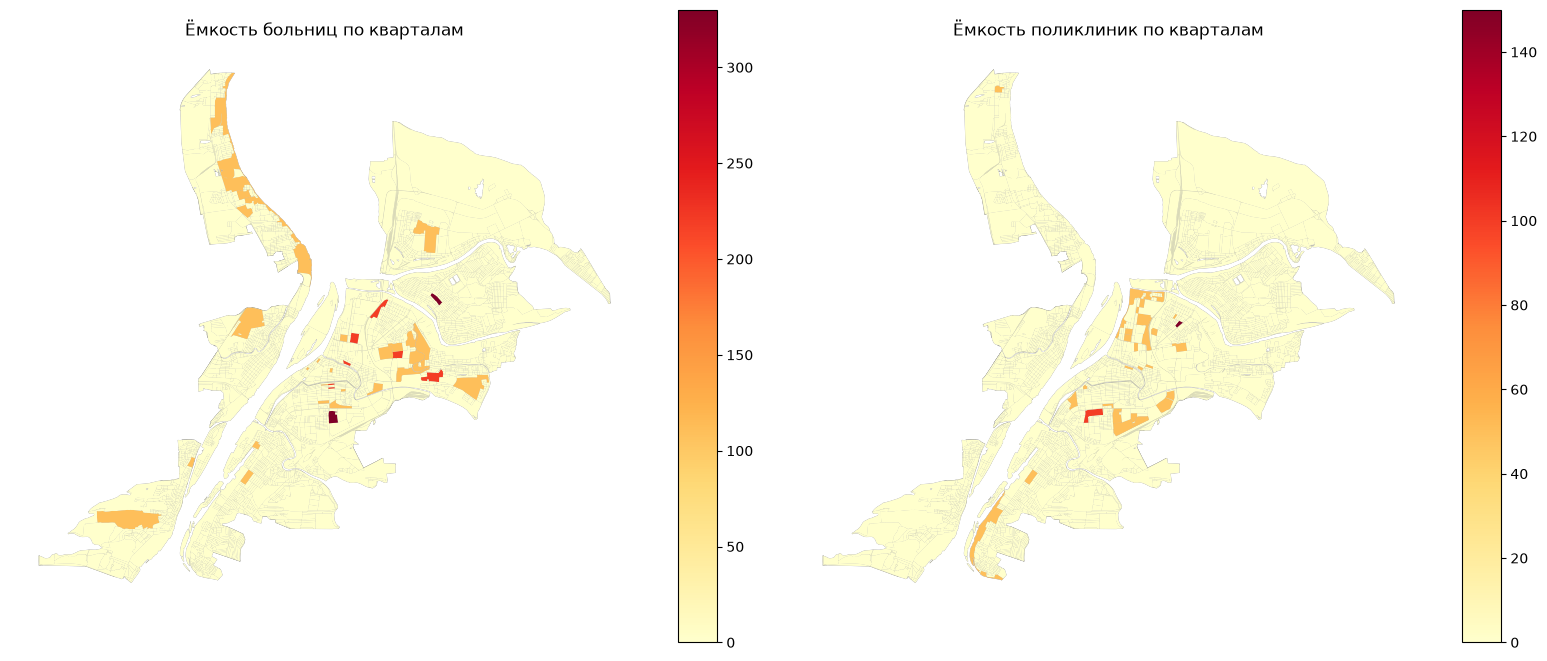

In [86]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, blocks_service, title in [
    (axes[0], hospitals_blocks, "Ёмкость больниц по кварталам"),
    (axes[1], polyclinics_blocks, "Ёмкость поликлиник по кварталам"),
]:
    blocks.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.3)
    blocks_service.plot(column="capacity", ax=ax, legend=True, cmap="YlOrRd")
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()


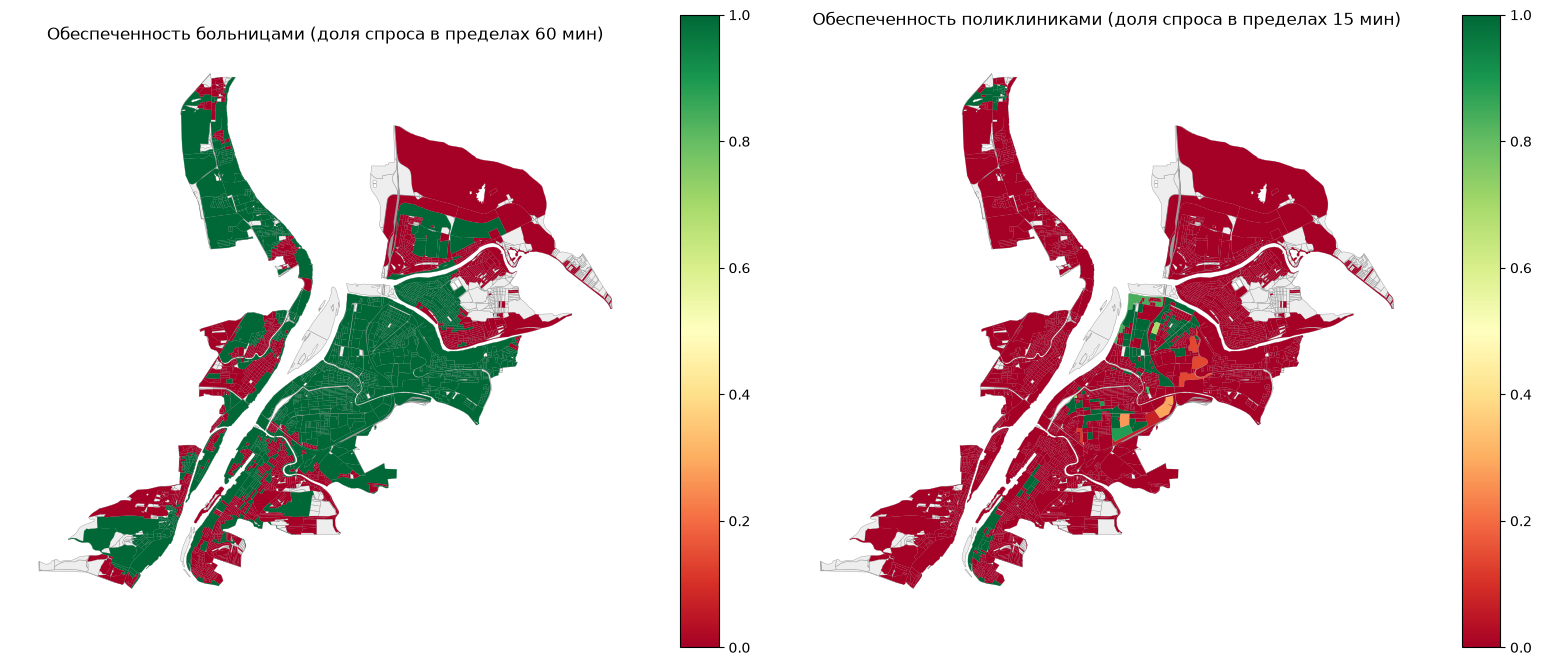

In [87]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

for ax, blocks_service, column, title in [
    (axes[0], hospitals_blocks, "hospital_provision_strong",
     "Обеспеченность больницами (доля спроса в пределах 60 мин)"),
    (axes[1], polyclinics_blocks, "polyclinic_provision_strong",
     "Обеспеченность поликлиниками (доля спроса в пределах 15 мин)"),
]:
    blocks.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.3)
    blocks_service.plot(
        column=column, ax=ax, legend=True, cmap="RdYlGn", vmin=0, vmax=1
    )
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()


## 8. Показатели из pipeline.ipynb

Здесь считаются оставшиеся показатели примера:

- **Density indicators** — FSI, GSI, MXI, L, OSR и доли жилой/нежилой площади.
- **Spacematrix morphotypes** — кластеризация кварталов по плотности и этажности.
- **Strelka morphotypes** — морфотипы по правилам Strelka.
- **Area accessibility** — средневзвешенная доступность территории (в минутах), взвешенная по площади кварталов.


In [88]:
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility

if "site_area" not in buildings_blocks.columns:
    buildings_blocks["site_area"] = buildings_blocks.area

density_df = calculate_density_indicators(buildings_blocks)
density_df = density_df.replace([np.inf, -np.inf], np.nan)
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
strelka_df = get_strelka_morphotypes(density_df)
area_acc = area_accessibility(acc_mx, buildings_blocks)

print("Плотностные показатели:")
display(density_df[["fsi", "gsi", "mxi", "l", "osr"]].describe().round(3))


Плотностные показатели:


,fsi,gsi,mxi,l,osr
count,4441.000,4441.000,3162.000,3162.000,3162.000
mean,0.115,0.085,0.878,1.226,77.782
std,0.229,0.090,0.109,1.079,2634.331
min,0.000,0.000,0.000,1.000,0.099
25%,0.000,0.000,0.900,1.000,4.820
50%,0.072,0.072,0.900,1.000,8.920
75%,0.131,0.126,0.900,1.000,14.465
max,6.263,0.910,0.900,24.428,146671.155


### 8.1. Таблицы плотности, морфотипов и доступности

Показываем первые строки всех таблиц, которые возвращают функции примера. `spacematrix_clusters` — это не кварталы, а центры кластеров: по ним видно, какие типы застройки выделил алгоритм. Для кварталов без застройки часть плотностных показателей может быть пустой.


In [89]:
print("Плотностные показатели:")
display(density_df.head())
display(
    density_df[
        ["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]
    ].describe().round(3)
)

print("Spacematrix по кварталам:")
display(spacematrix_df.head())

print("Центры кластеров Spacematrix:")
display(spacematrix_clusters)

print("Strelka по кварталам:")
display(strelka_df.head())

print("Доступность территории:")
display(area_acc.head())


Плотностные показатели:


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,1583.840216,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1,66.467263,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
2,2176.793518,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
3,31807.750521,625.157840,625.157840,562.642056,62.515784,0.019654,0.019654,0.9,1.0,49.879552,0.9,0.1
4,35447.395578,1217.544583,1217.544583,1095.790125,121.754458,0.034348,0.034348,0.9,1.0,28.113838,0.9,0.1


,fsi,gsi,mxi,l,osr,share_living,share_non_living
count,4441.000,4441.000,3162.000,3162.000,3162.000,3162.000,3162.000
mean,0.115,0.085,0.878,1.226,77.782,1.052,0.174
std,0.229,0.090,0.109,1.079,2634.331,0.851,0.540
min,0.000,0.000,0.000,1.000,0.099,0.000,0.100
25%,0.000,0.000,0.900,1.000,4.820,0.900,0.100
50%,0.072,0.072,0.900,1.000,8.920,0.900,0.100
75%,0.131,0.126,0.900,1.000,14.465,0.900,0.100
max,6.263,0.910,0.900,24.428,146671.155,16.293,24.428


Spacematrix по кварталам:


,l,fsi,mxi,cluster,morphotype
0,0.0,0.000000,0.0,NaN,NaN
1,0.0,0.000000,0.0,NaN,NaN
2,0.0,0.000000,0.0,NaN,NaN
3,1.0,0.019654,0.9,0.0,low-rise low-density residential
4,1.0,0.034348,0.9,0.0,low-rise low-density residential


...

,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.084711,0.900000,low-rise,low-density,residential,low-rise low-density residential
1,8.323930,1.577927,0.900000,high-mid-rise,None,residential,high-mid-rise residential
2,1.004216,0.183888,0.099998,low-rise,low-density,non-residential,low-rise low-density non-residential
3,3.915419,0.645204,0.900000,mid-rise,low-density,residential,mid-rise low-density residential
4,24.428114,6.263030,0.000000,tower,high-density,non-residential,tower high-density non-residential
5,1.127482,0.196706,0.649279,low-rise,low-density,residential,low-rise low-density residential
6,18.103663,1.663935,0.900000,tower,None,residential,tower residential
7,12.000000,4.782102,0.900000,high-rise,high-density,residential,high-rise high-density residential
8,5.347967,1.699879,0.139565,mid-rise,None,non-residential,mid-rise non-residential


Strelka по кварталам:


,l,fsi,mxi,morphotype
0,0.0,0.000000,0.0,NaN
1,0.0,0.000000,0.0,NaN
2,0.0,0.000000,0.0,NaN
3,1.0,0.019654,0.9,individual residential
4,1.0,0.034348,0.9,individual residential


Доступность территории:


,area_accessibility
0,204.005786
1,204.906191
2,199.940614
3,195.772909
4,198.032617


### 8.2. Карты плотности и этажности

Четыре карты показывают, как по городу распределены плотность застройки, доля застроенной земли, доля жилья и средняя этажность. Это помогает увидеть центр, частный сектор и промышленные зоны.


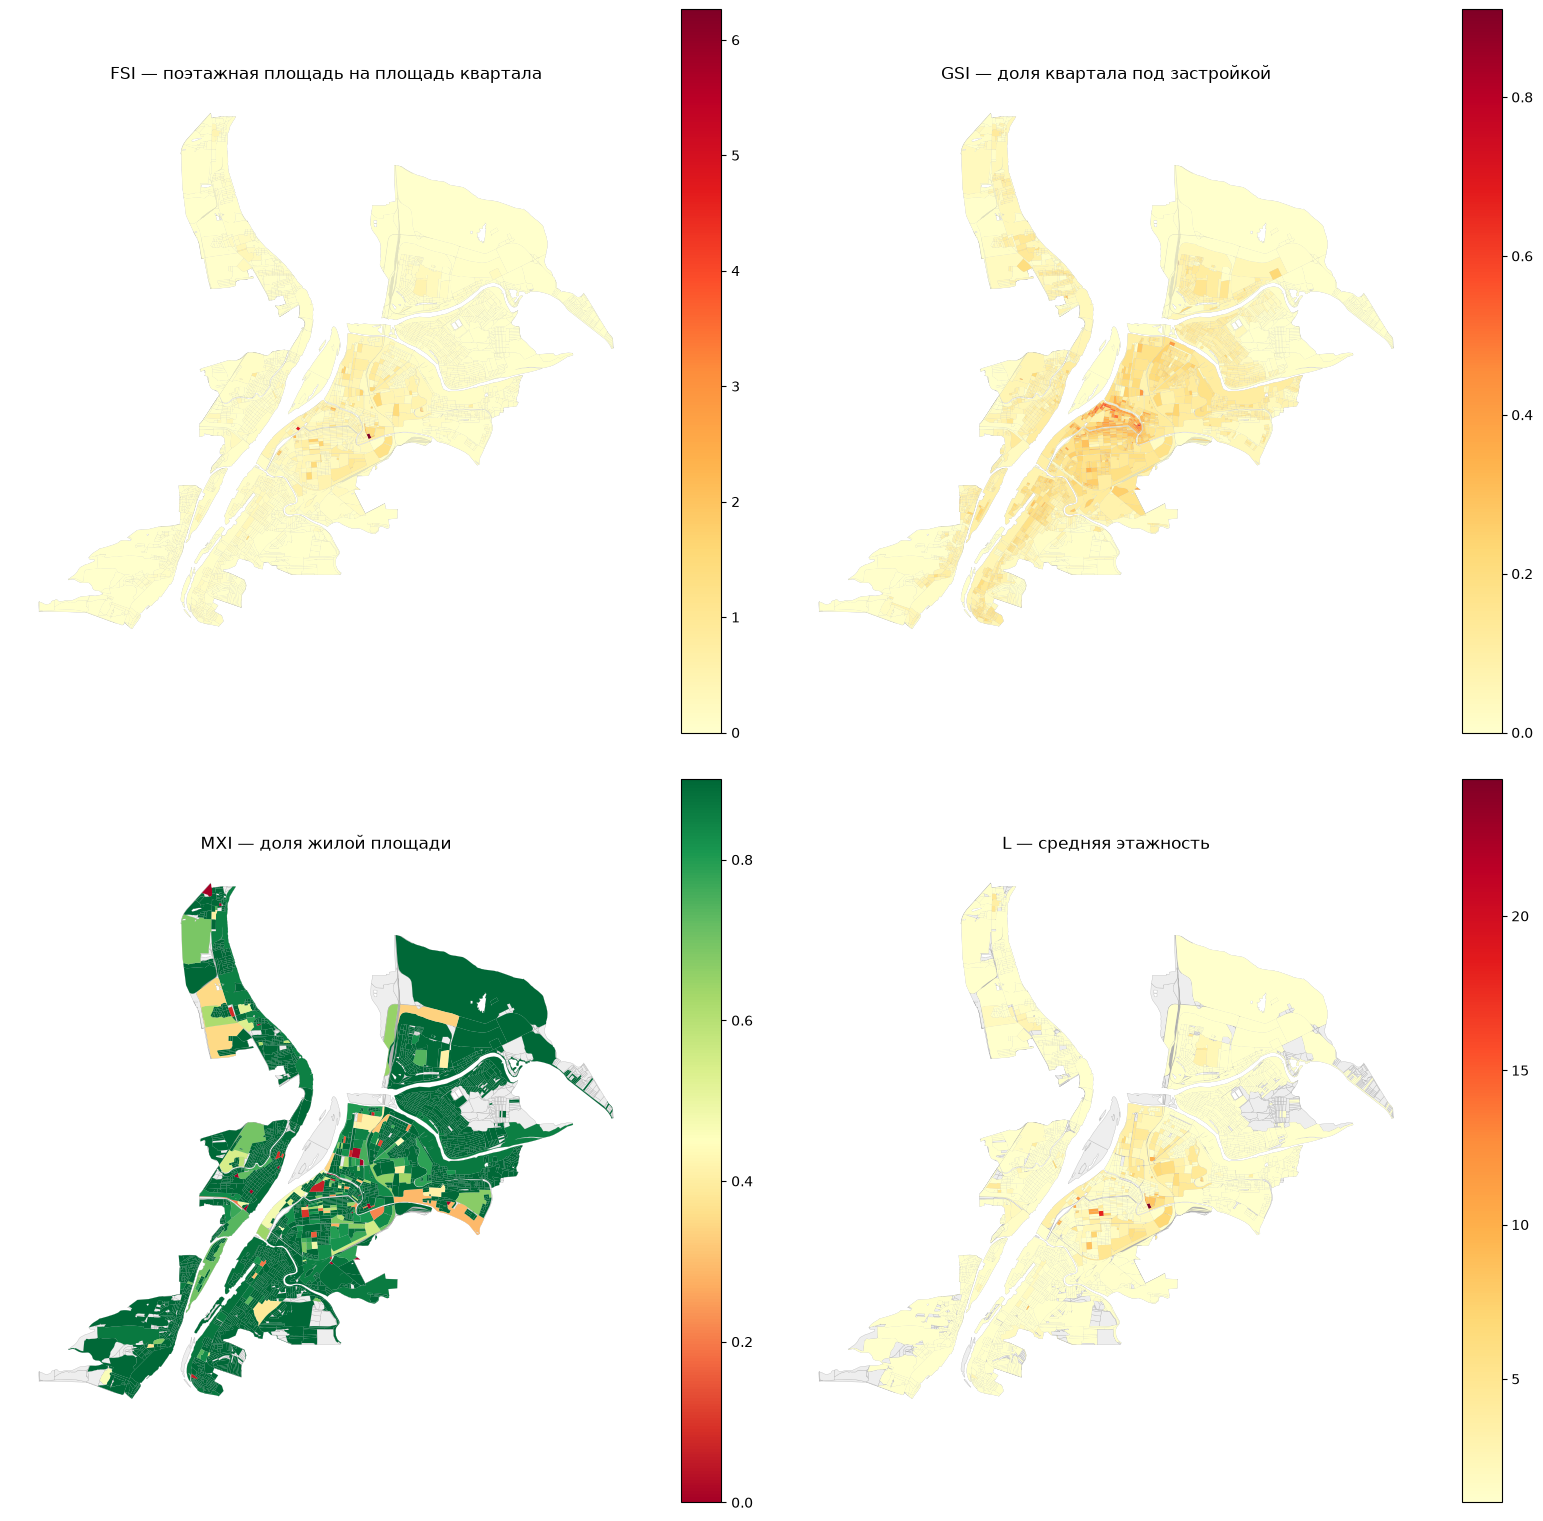

In [90]:
density_map = blocks.join(density_df[["fsi", "gsi", "mxi", "l"]])

fig, axes = plt.subplots(2, 2, figsize=(16, 16))

for ax, column, title, cmap in [
    (axes[0, 0], "fsi", "FSI — поэтажная площадь на площадь квартала", "YlOrRd"),
    (axes[0, 1], "gsi", "GSI — доля квартала под застройкой", "YlOrRd"),
    (axes[1, 0], "mxi", "MXI — доля жилой площади", "RdYlGn"),
    (axes[1, 1], "l", "L — средняя этажность", "YlOrRd"),
]:
    density_map.plot(ax=ax, color="#eeeeee", edgecolor="#aaaaaa", linewidth=0.2)
    density_map.plot(column=column, ax=ax, legend=True, cmap=cmap)
    ax.set_title(title)
    ax.set_axis_off()

plt.tight_layout()
plt.show()


### 8.3. Карта морфотипов Spacematrix

Spacematrix разбивает застроенные кварталы на кластеры по этажности, плотности и доле жилья. На карте цвет — это тип квартала, а не числовой показатель.


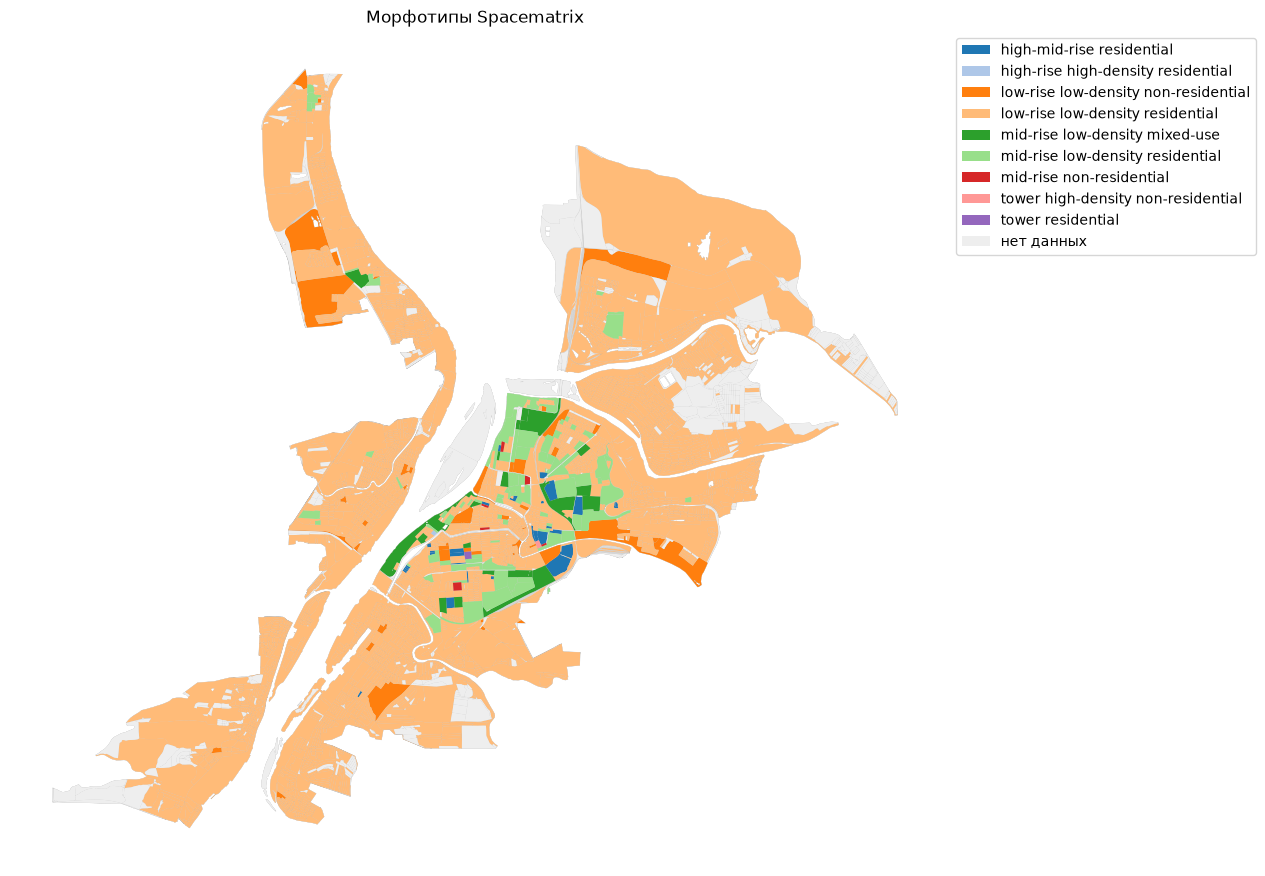

In [91]:
spacematrix_map = blocks.join(spacematrix_df[["cluster", "morphotype"]])

fig, ax = plt.subplots(figsize=(12, 12))
spacematrix_map.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.2)
spacematrix_map.plot(
    column="morphotype",
    ax=ax,
    legend=True,
    categorical=True,
    cmap="tab20",
    missing_kwds={"color": "#eeeeee", "label": "нет данных"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1)},
)
ax.set_title("Морфотипы Spacematrix")
ax.set_axis_off()
plt.show()


### 8.4. Карта морфотипов Strelka

Strelka определяет тип квартала по правилам, без кластеризации. Карта помогает сравнить формальную типологию с Spacematrix: границы типов обычно похожи, но названия Strelka понятнее.


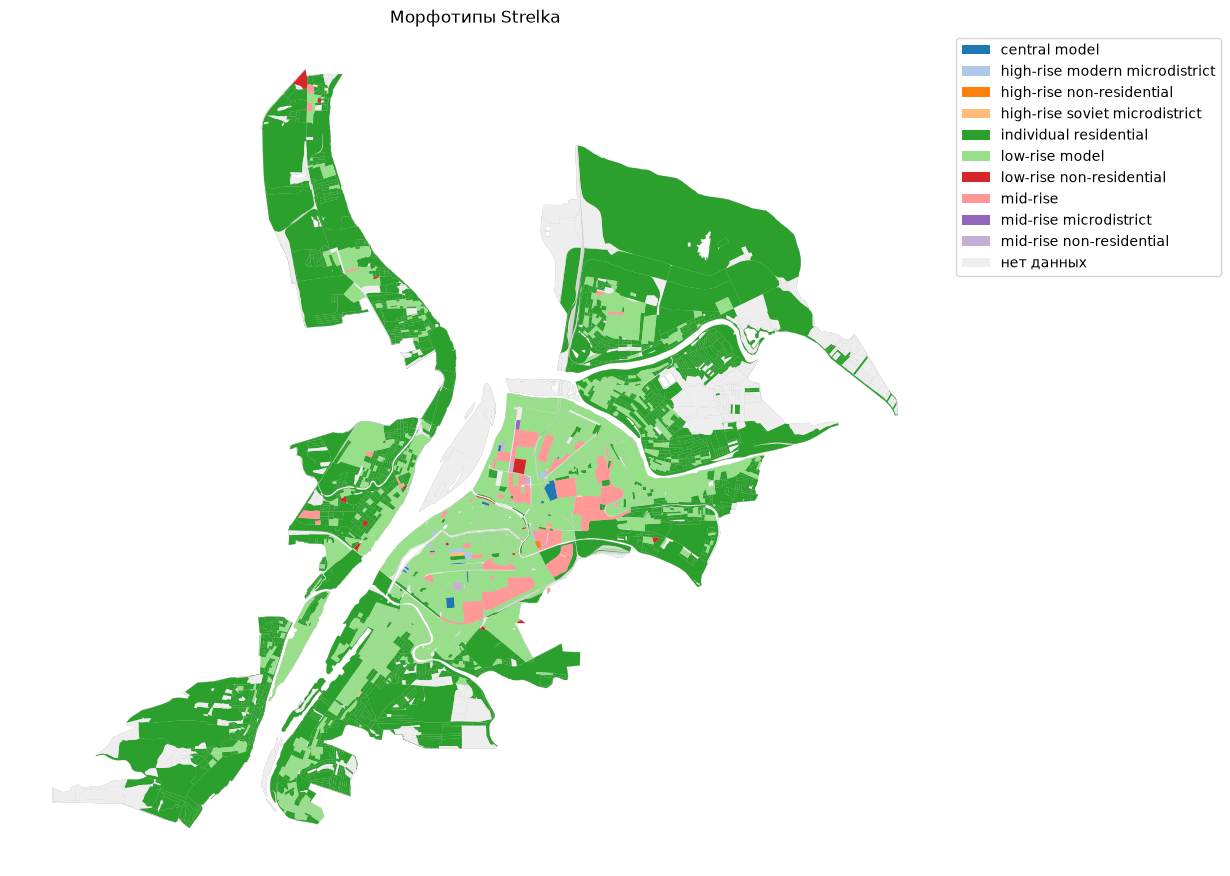

In [92]:
strelka_map = blocks.join(strelka_df[["morphotype"]])

fig, ax = plt.subplots(figsize=(12, 12))
strelka_map.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.2)
strelka_map.plot(
    column="morphotype",
    ax=ax,
    legend=True,
    categorical=True,
    cmap="tab20",
    missing_kwds={"color": "#eeeeee", "label": "нет данных"},
    legend_kwds={"loc": "upper left", "bbox_to_anchor": (1.01, 1)},
)
ax.set_title("Морфотипы Strelka")
ax.set_axis_off()
plt.show()


### 8.5. Карта доступности территории

Показатель `area_accessibility` — средневзвешенное время пешком до всех кварталов, минуты. Чем меньше значение, тем лучше квартал связан с городом. Зелёный цвет — высокая доступность, красный — низкая.


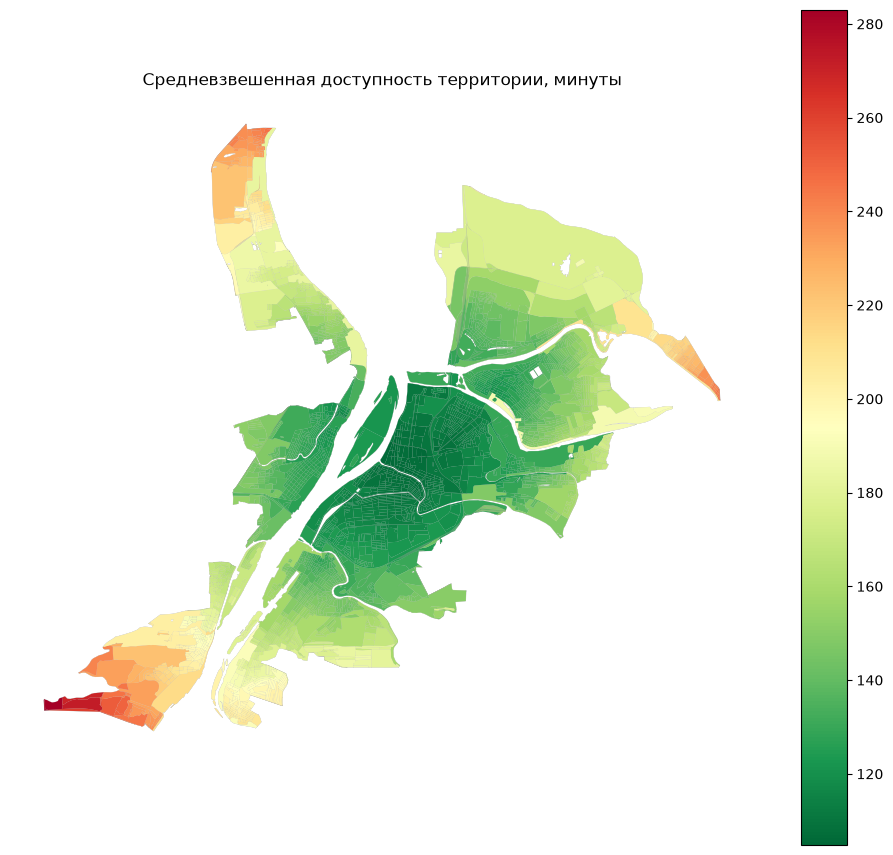

In [93]:
area_map = blocks.join(area_acc)

fig, ax = plt.subplots(figsize=(12, 12))
area_map.plot(ax=ax, color="#eeeeee", edgecolor="#999999", linewidth=0.2)
area_map.plot(
    column="area_accessibility",
    ax=ax,
    legend=True,
    cmap="RdYlGn_r",
)
ax.set_title("Средневзвешенная доступность территории, минуты")
ax.set_axis_off()
plt.show()


### 8.6. Итоговая таблица показателей

Собираем всё в один слой `blocks_indicators.geojson`: агрегаты зданий, плотности, морфотипы, доступность и обеспеченность. Именно этот файл потом станет основой для HTML-карты и дашборда.


In [94]:
result = blocks.copy()

building_columns = [
    "population", "population_calibrated", "count", "footprint_area",
    "build_floor_area", "living_area", "non_living_area",
    "number_of_floors", "is_living",
]
result = result.join(
    buildings_blocks[building_columns].rename(columns={"count": "building_count"})
)
result = result.join(
    hospitals_blocks[["count"]].rename(columns={"count": "hospital_count"})
)
result = result.join(
    polyclinics_blocks[["count"]].rename(columns={"count": "polyclinic_count"})
)
result = result.join(hospitals_provision)
result = result.join(polyclinics_provision)
result = result.join(
    density_df[["fsi", "gsi", "mxi", "l", "osr", "share_living", "share_non_living"]]
)
result = result.join(
    spacematrix_df[["cluster", "morphotype"]].rename(
        columns={"cluster": "spacematrix_cluster", "morphotype": "spacematrix_morphotype"}
    )
)
result = result.join(
    strelka_df[["morphotype"]].rename(columns={"morphotype": "strelka_morphotype"})
)
result = result.join(area_acc)

write_gdf(result, "blocks_indicators.geojson")
write_csv(density_df, "density_indicators.csv")
write_csv(spacematrix_df, "spacematrix_morphotypes.csv")
write_csv(spacematrix_clusters, "spacematrix_clusters.csv")
write_csv(strelka_df, "strelka_morphotypes.csv")
write_csv(area_acc, "area_accessibility.csv")

print("Итоговый слой сохранён. Колонок:", len(result.columns))


Сохранено: blocks_indicators.geojson (4441 объектов)
Сохранено: density_indicators.csv
Сохранено: spacematrix_morphotypes.csv
Сохранено: spacematrix_clusters.csv
Сохранено: strelka_morphotypes.csv
Сохранено: area_accessibility.csv
Итоговый слой сохранён. Колонок: 52


## 9. Проверка результатов

Ячейка ниже ничего не пересчитывает: она проверяет, что данные согласованы, и печатает сводку.


In [95]:
matrix_values = acc_mx.to_numpy(dtype="float64", copy=True)
off_diagonal = ~np.eye(acc_mx.shape[0], dtype=bool)
matrix_values = matrix_values[off_diagonal]
finite_values = matrix_values[np.isfinite(matrix_values)]

same_index = result.index.equals(acc_mx.index) and acc_mx.index.equals(acc_mx.columns)
values = acc_mx.to_numpy(dtype="float64")
finite = np.isfinite(values) & np.isfinite(values.T)
symmetry_error = np.abs(values[finite] - values.T[finite]).max() if finite.any() else np.nan

summary = pd.DataFrame(
    [
        ("Кварталов", len(result)),
        ("Система координат", str(result.crs)),
        ("Население, всего (калиброванное)", int(round(result["population_calibrated"].sum()))),
        ("Население, всего (модельное до калибровки)", int(result["population"].sum())),
        ("Кварталов без населения (калиброванное)", int((result["population_calibrated"] == 0).sum())),
        ("Матрица доступности", f"{acc_mx.shape[0]} x {acc_mx.shape[1]}"),
        ("Индекс совпадает с матрицей", same_index),
        ("Максимальная асимметрия матрицы, мин", round(float(symmetry_error), 4)),
        ("Доля пар без маршрута, %", round(float((~np.isfinite(matrix_values)).mean() * 100), 2)),
        ("Кварталов с больницей", int((result["hospital_count"] > 0).sum())),
        ("Кварталов с поликлиникой", int((result["polyclinic_count"] > 0).sum())),
        ("Кварталов с обеспеченностью больницами > 0", int((result["hospital_provision_strong"] > 0).sum())),
        ("Кварталов с обеспеченностью поликлиниками > 0", int((result["polyclinic_provision_strong"] > 0).sum())),
        ("Пропусков population_calibrated", int(result["population_calibrated"].isna().sum())),
        ("Пропусков fsi", int(result["fsi"].isna().sum())),
    ],
    columns=["Показатель", "Значение"],
)
display(summary)

print("Морфотипы Spacematrix:")
print(result["spacematrix_morphotype"].value_counts(dropna=False).to_string())
print()
print("Морфотипы Strelka:")
print(result["strelka_morphotype"].value_counts(dropna=False).to_string())


,Показатель,Значение
0,Кварталов,4441
1,Система координат,EPSG:32639
2,"Население, всего (калиброванное)",465990
3,"Население, всего (модельное до калибровки)",510208
4,Кварталов без населения (калиброванное),1295
5,Матрица доступности,4441 x 4441
6,Индекс совпадает с матрицей,True
7,"Максимальная асимметрия матрицы, мин",3.3
8,"Доля пар без маршрута, %",0.0
9,Кварталов с больницей,32


Морфотипы Spacematrix:
spacematrix_morphotype
low-rise low-density residential        2973
NaN                                     1279
mid-rise low-density residential          86
low-rise low-density non-residential      45
high-mid-rise residential                 30
mid-rise low-density mixed-use            19
mid-rise non-residential                   6
tower high-density non-residential         1
tower residential                          1
high-rise high-density residential         1

Морфотипы Strelka:
strelka_morphotype
individual residential            1558
low-rise model                    1504
NaN                               1279
mid-rise                            55
low-rise non-residential            15
central model                       10
high-rise modern microdistrict      10
mid-rise non-residential             5
high-rise soviet microdistrict       3
high-rise non-residential            1
mid-rise microdistrict               1


In [96]:
print("Файлы в папке данных:")
for path in sorted(DATA_DIR.glob("*")):
    size_mb = path.stat().st_size / 1024 / 1024
    print(f" - {path.name}: {size_mb:.1f} МБ")


Файлы в папке данных:
 - accessibility_matrix.csv: 111.0 МБ
 - area_accessibility.csv: 0.1 МБ
 - blocks.geojson: 5.1 МБ
 - blocks_indicators.geojson: 10.2 МБ
 - blocks_raw.geojson: 4.3 МБ
 - boundaries.geojson: 0.1 МБ
 - buildings.geojson: 28.1 МБ
 - buildings_blocks.geojson: 5.4 МБ
 - density_indicators.csv: 0.7 МБ
 - functional_zones.geojson: 1.0 МБ
 - hospitals.geojson: 0.0 МБ
 - hospitals_blocks.geojson: 4.7 МБ
 - hospitals_links.csv: 0.0 МБ
 - hospitals_provision.csv: 0.1 МБ
 - polyclinics.geojson: 0.0 МБ
 - polyclinics_blocks.geojson: 4.8 МБ
 - polyclinics_links.csv: 0.0 МБ
 - polyclinics_provision.csv: 0.1 МБ
 - railways.geojson: 0.3 МБ
 - roads.geojson: 2.4 МБ
 - south-fed-district-latest.osm.pbf: 301.7 МБ
 - spacematrix_clusters.csv: 0.0 МБ
 - spacematrix_morphotypes.csv: 0.3 МБ
 - strelka_morphotypes.csv: 0.2 МБ
 - walk_graph.graphml: 21.8 МБ
 - water.geojson: 0.4 МБ


## 10. Повторный запуск

Обычный сценарий: откройте ноутбук, выберите ядро `.venv` и выполняйте ячейки сверху вниз.

- Если файл уже есть в `examples/data/astrakhan/`, ячейка прочитает его и не будет скачивать данные или считать заново.
- Чтобы пересчитать только один шаг, удалите соответствующий файл или временно поставьте `FORCE_RECALC = True`.
- `FORCE_RECALC = True` пересчитывает всё, включая долгие матрицу доступности и расчёт обеспеченности.
- Если скачивание PBF прервалось, запустите ячейку ещё раз. Уже сохранённые слои не пострадают.
- Ориентировочное время первого полного прогона для всего города — от нескольких десятков минут. Повторный прогон по кэшу занимает минуты.

Файлы кэша:

- `south-fed-district-latest.osm.pbf` — исходная выгрузка OSM (~316 МБ);
- `boundaries.geojson` — граница города;
- `roads.geojson`, `railways.geojson`, `water.geojson` — данные OSM;
- `functional_zones.geojson` — зоны land use;
- `blocks_raw.geojson`, `blocks.geojson` — кварталы;
- `walk_graph.graphml` — пешеходный граф;
- `accessibility_matrix.csv` — матрица времени в пути;
- `buildings.geojson`, `buildings_blocks.geojson` — здания и их агрегация;
- `hospitals*.geojson`, `polyclinics*.geojson` — услуги и их агрегация;
- `blocks_indicators.geojson` — итоговый слой;
- CSV-таблицы с показателями и связями.


## 11. Что дальше

После проверки результатов отдельным этапом будет подготовлен Python-файл, который соберёт одну HTML-страницу:

- интерактивную карту кварталов (например, на Folium);
- дашборд с теми же показателями;
- графики и таблицы;
- краткие выводы по территории.

Данные для этой страницы берутся из `blocks_indicators.geojson` и CSV-файлов, созданных этим ноутбуком.
